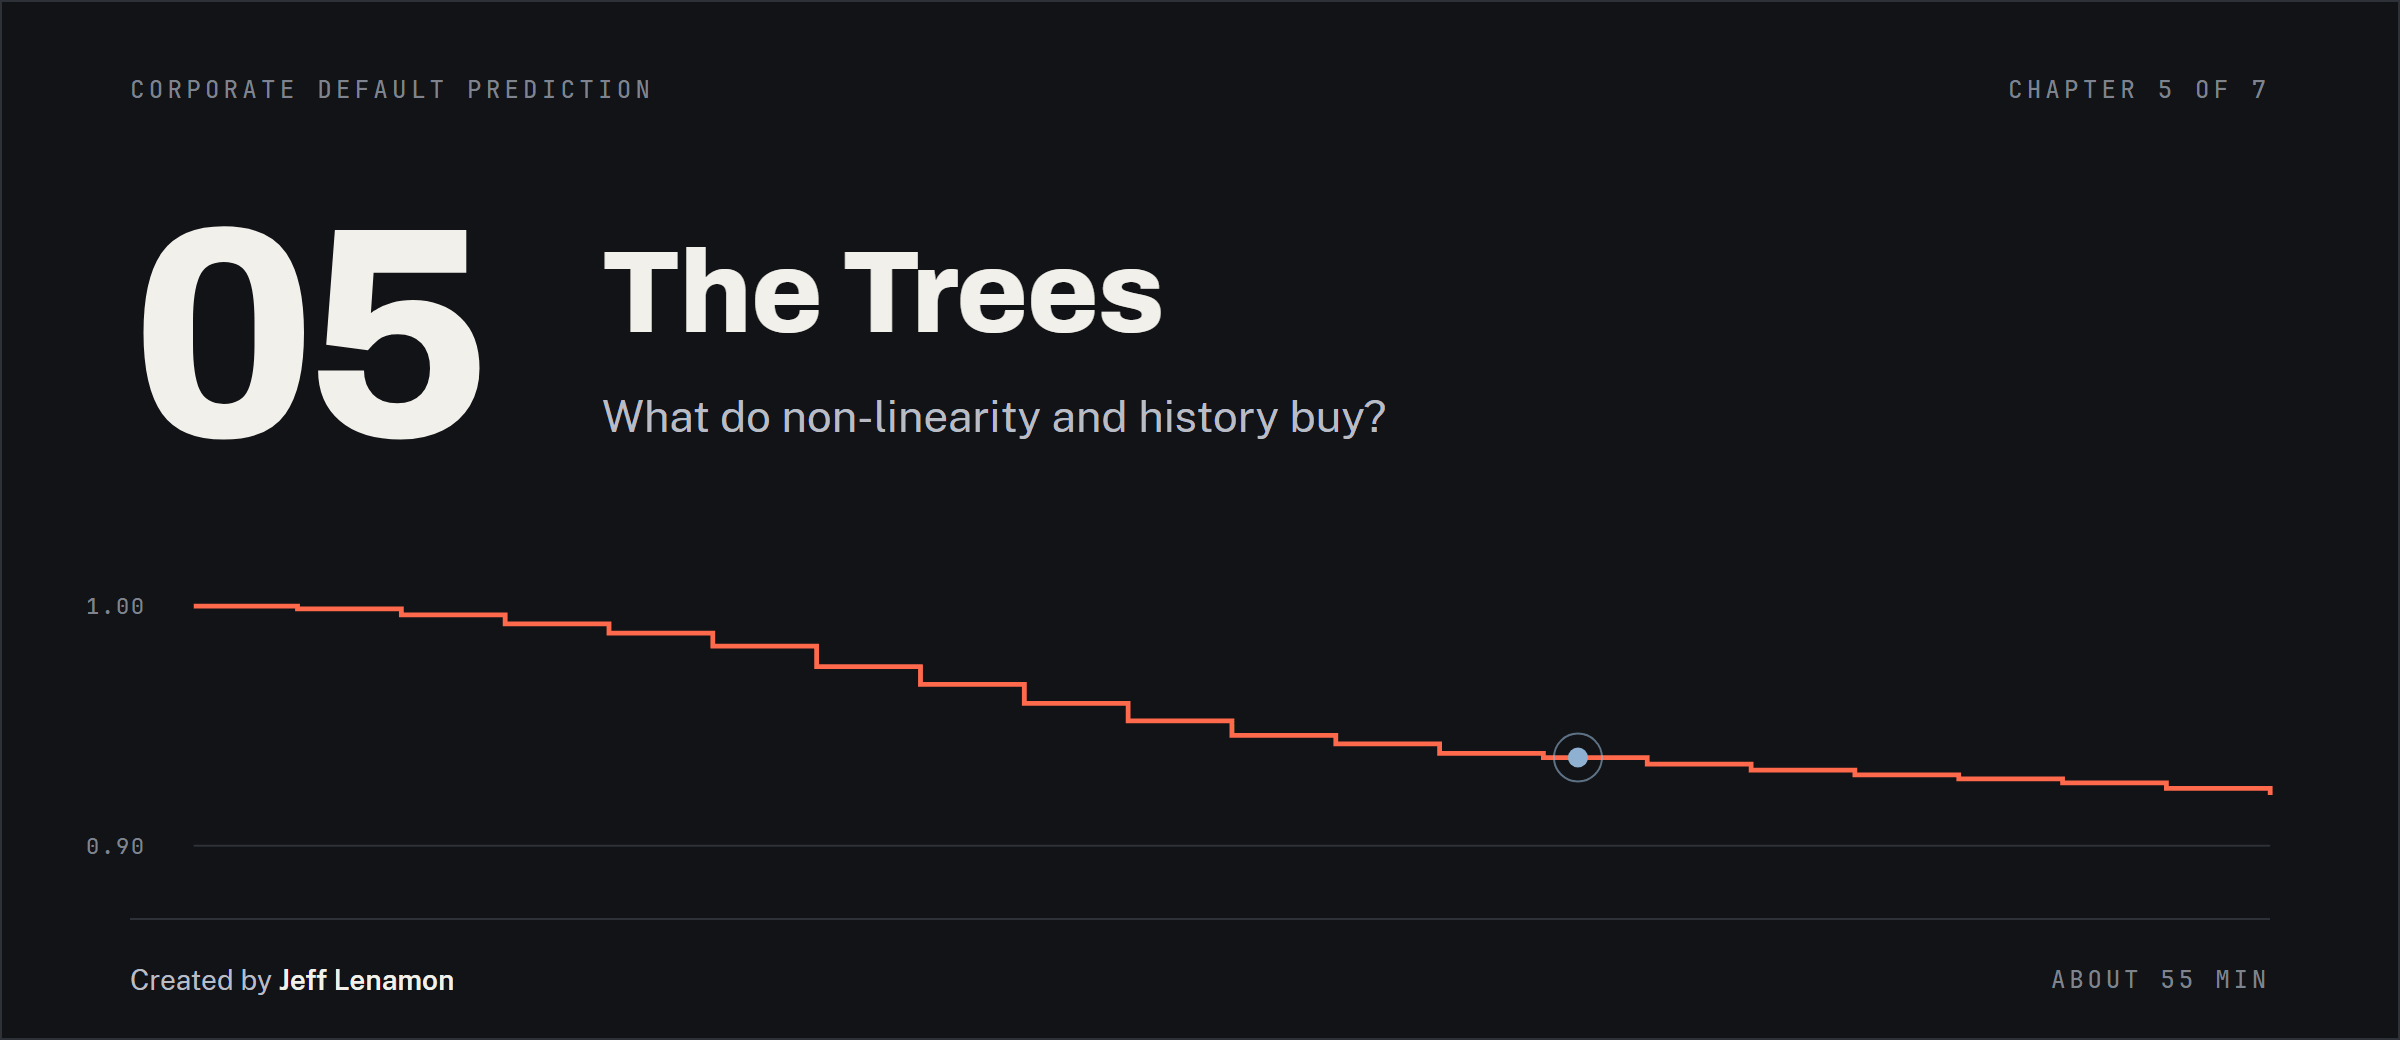

# Chapter 5: The Trees

What boosted trees add to the ratios, how to tune them without fooling yourself, and what a company's history is worth.

> This casebook is educational content created in a personal capacity

> Nothing here is investment advice or a recommendation to buy or sell any security

> The data is a public research dataset with anonymised company names

## The Question

Chapter 4 ended on a logistic regression over every ratio.
It can only add the ratios up, each with one weight.

Chapter 3 found curves that bend, a risk map whose corner matters, and failed firms that decay for years.
What do non-linearity and history buy?

## What You Will Learn

By the end you can:

- read a boosted model as a sum of small trees;
- leave rare failures unweighted, and say why;
- tell a real gain from the noise of one validation window;
- choose the settings, and the number of trees, on the walk-forward;
- test a block of inputs, or a constraint, with a paired difference.

## What You Need

Chapter 3, which wrote the `features` table, and Chapter 4, which wrote the out-of-fold scores of the first three rungs.
Chapter 4 also explains the folds, the percentile ranking, and the paired difference.

The chapter fits several hundred models, so it takes longer to run than any chapter before it.
The slow cells say so.

It adds two rungs to the table of scores, and the settings of the tree model to the record of how each model is built.

## Your Route

![Your route through Chapter 5: 1 Setting Up, 5 minutes; 2 One Tree, Then Many, 4 minutes; 3 Imbalance Without Tricks, 3 minutes; 4 How Noisy Is a Validation Score, 4 minutes; 5 Tuning on a Walk-Forward, 8 minutes; 6 The Snapshot Model, 1 minute; 7 Adding History, 5 minutes; 8 Do Raw Dollars and Industry Earn Their Place, 3 minutes; 9 Building In What We Know, 5 minutes; 10 The Ladder So Far, 6 minutes.](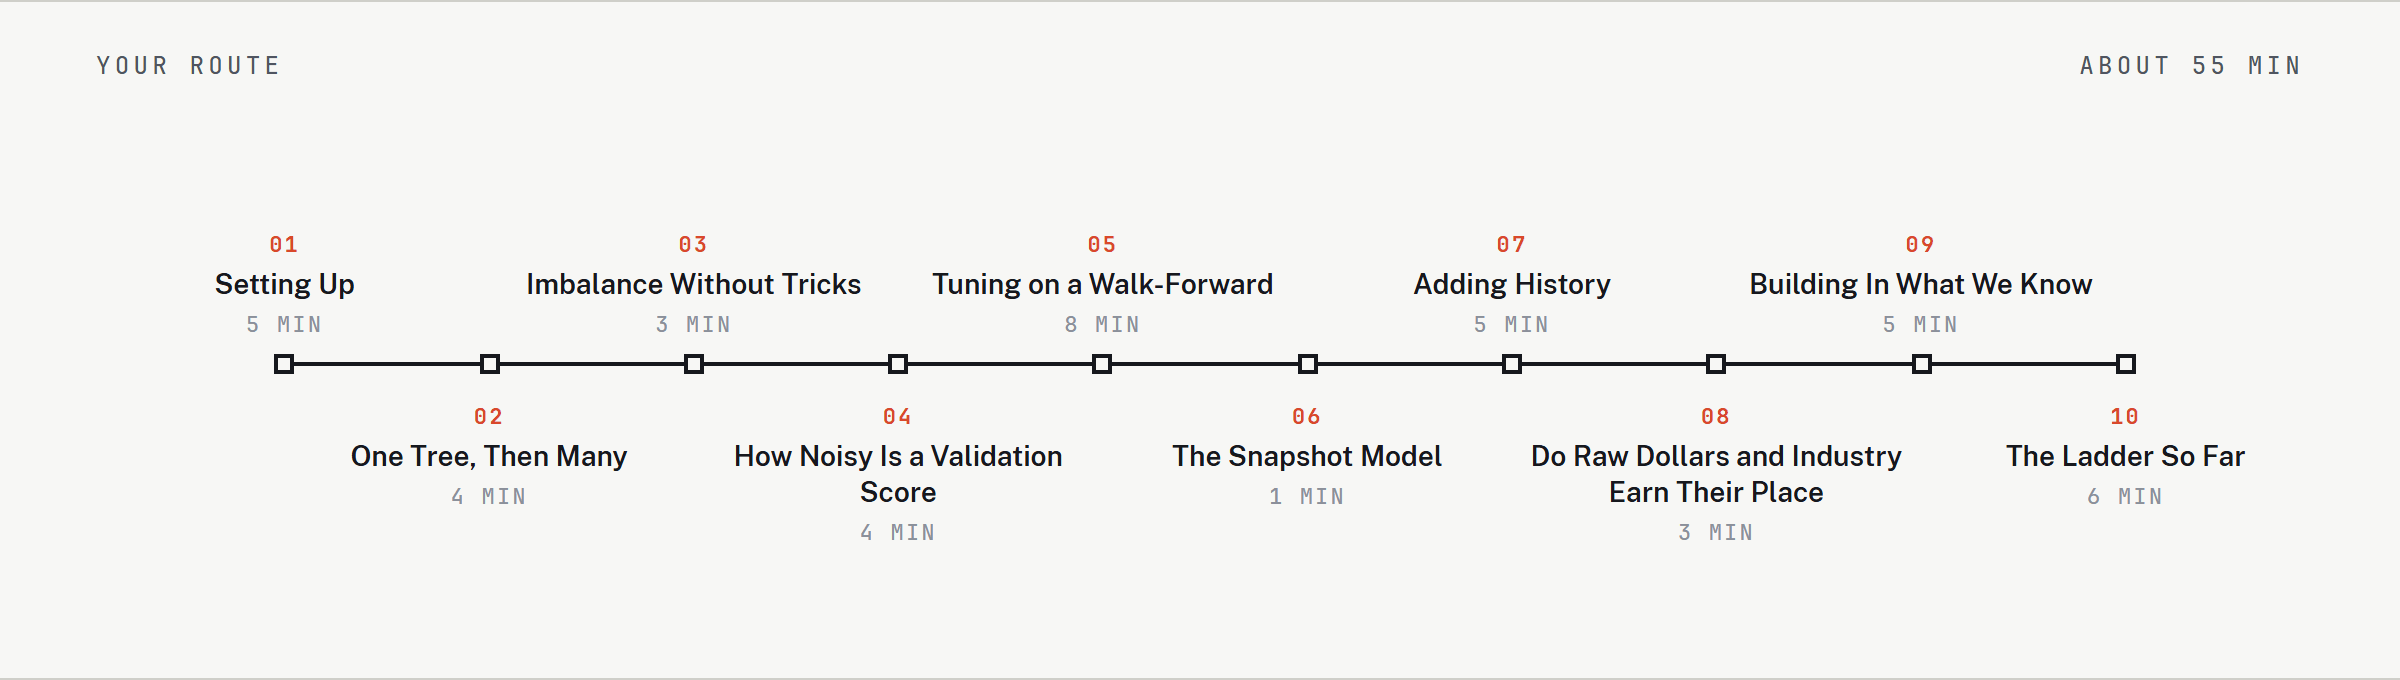)

**Time.** About 47 minutes to read and run, then about 9 for Your Turn.

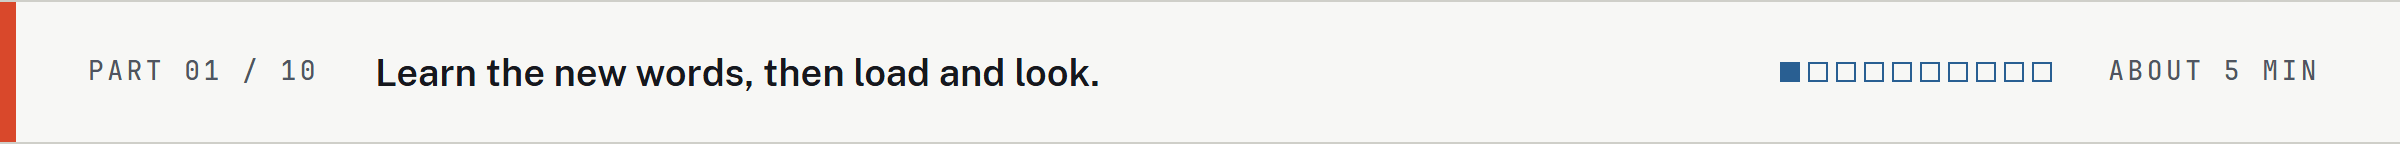

# Setting Up

Make sure the Jupyter kernel `corp-default` is selected before you run a cell.
If it is not in the list, or an import fails, the [Quick Start](../README.md#quick-start) shows how to register it and refresh the list.

## The Data Dictionary

The chapter reads `features` and the out-of-fold scores of Chapter 4.
It builds no column of its own: it offers a model four blocks of columns that earlier chapters built.

| Block | Columns | Built in |
| --- | --- | --- |
| **Ratios** | The 24 ratios, in seven families | Chapter 3 |
| **History** | 21 columns: changes over one and two years, growth, past losses, years observed | Chapter 3 |
| **Raw dollars** | The 17 dollar items of the file | Chapter 1 |
| **Industry** | The SIC `division` and `major_group` of each company | Chapter 1 |

Five words describe a boosted tree model.

| Term | What it means |
| --- | --- |
| **Tree** | A short list of yes-or-no questions about the inputs, ending in a score |
| **Round** | One tree added to the model, so a model of two hundred rounds is a sum of two hundred trees |
| **Depth** | How many questions a row answers on its way down one tree |
| **Learning rate** | The fraction of each new tree that is added to the sum |
| **Configuration** | One choice of depth, learning rate, and the other settings |

Q. What does the chapter need before it starts?

In [1]:
import os
from collections.abc import Callable
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import MultipleLocator, PercentFormatter
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import ParameterSampler
from xgboost import XGBClassifier

from corp_default import store, viz
from corp_default.data import RAW_ITEMS
from corp_default.evaluate import KEYS, SEED, fold_table, paired_table, scoreboard
from corp_default.features import FAMILIES, feature_names, fit_prepare
from corp_default.metrics import wilson_interval, within_year_percentile
from corp_default.splits import CRISIS_FOLDS, FOLD_YEARS, Fold, development, walk_forward_folds

store.open_chapter(5)
viz.use_house_style()
SOURCE = "Lombardo et al. (2022), Kaggle copy"
OOF_SOURCE = f"{SOURCE}; out-of-fold rows, {FOLD_YEARS[0]} to {FOLD_YEARS[-1]}"
TREES = viz.MODEL_COLORS["trees"]
CORES = os.cpu_count()

features = store.load_frame("features")
earlier = store.load_frame("oof_scores")

**Reading.** The table of Chapter 3 and the scores of Chapter 4 are in memory, and the house style is set for every chart.
`store.put` carries a number from a cell into the text, so no number in this chapter is typed by hand.

Q. What do the scores of Chapter 4 look like?

In [2]:
earlier.head()

,company_name,year,target,score,pct,model
0,C_1,2005,0,-2.878107,0.550540,Altman Z
1,C_2,2005,0,-2.412993,0.610324,Altman Z
2,C_3,2005,0,-6.339636,0.217767,Altman Z
3,C_4,2005,0,-1.971397,0.674670,Altman Z
4,C_6,2005,0,-0.554995,0.818968,Altman Z


**Reading.** Each row is one firm-year scored by one model: the score, and its percentile within the year.

Q. How large are the two tables, and what does the table of scores hold?

In [3]:
RATIOS = [name for members in FAMILIES.values() for name in members]
ALL = feature_names()
HISTORY = [name for name in ALL if name not in RATIOS]
NEW = ["All ratios, trees", "Plus history"]
# A second run of this chapter finds its own two rungs in the file, and sets them aside.
earlier = earlier.loc[~earlier["model"].isin(NEW)].reset_index(drop=True)

dev = development(features).reset_index(drop=True)
folds = walk_forward_folds(dev)
last = folds[-1]
train_last, valid_last = dev.loc[last.train], dev.loc[last.valid]

store.put("n_ratios", len(RATIOS))
store.put("n_history", len(HISTORY))
store.put("n_raw", len(RAW_ITEMS))
store.put("n_folds", len(folds))
store.put("one_in", round(1 / dev["target"].mean()))

print(features.shape, dev.shape)
earlier.info()

(72393, 73) (55524, 73)
<class 'pandas.DataFrame'>
RangeIndex: 80367 entries, 0 to 80366
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   company_name  80367 non-null  str    
 1   year          80367 non-null  int64  
 2   target        80367 non-null  int64  
 3   score         80367 non-null  float64
 4   pct           80367 non-null  float64
 5   model         80367 non-null  str    
dtypes: float64(2), int64(2), str(2)
memory usage: 3.7 MB


**Reading.** The development years hold 66 firm-years for each one that fails within two years.
The table of scores holds the same out-of-fold rows three times, once for each rung of Chapter 4.

Q. What do the history columns hold?

In [4]:
dev[HISTORY].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
d1_roa,47262.0,-0.123,12.155,-1509.561,-0.056,-0.001,0.042,542.654
d1_liabilities_to_assets,47262.0,0.306,30.987,-2413.896,-0.042,0.002,0.059,3064.821
d1_working_capital_to_assets,47262.0,-0.297,27.885,-3064.821,-0.062,-0.001,0.049,2413.870
d1_mve_to_liabilities,47262.0,-2.031,139.126,-15168.160,-1.103,-0.051,0.591,17612.940
d1_ebitda_margin,47262.0,-0.518,178.682,-27073.900,-0.030,0.002,0.037,14650.400
d1_ebitda_to_assets,47262.0,-0.057,7.964,-1220.099,-0.042,0.000,0.035,322.250
g1_sales,47249.0,0.082,0.580,-8.972,-0.053,0.071,0.208,9.383
g1_assets,47262.0,0.049,0.446,-5.791,-0.081,0.037,0.162,7.668
g1_market_cap,47262.0,-0.036,0.847,-10.373,-0.383,0.026,0.363,11.294
loss_1y_ago,47262.0,0.414,0.493,0.000,0.000,0.000,1.000,1.000


**Reading.** The counts differ because history has blanks: a change over two years needs a filing two years earlier.
A tree takes a blank as it is, and learns at each question which way a blank should go.

**Next, what one tree looks like.**

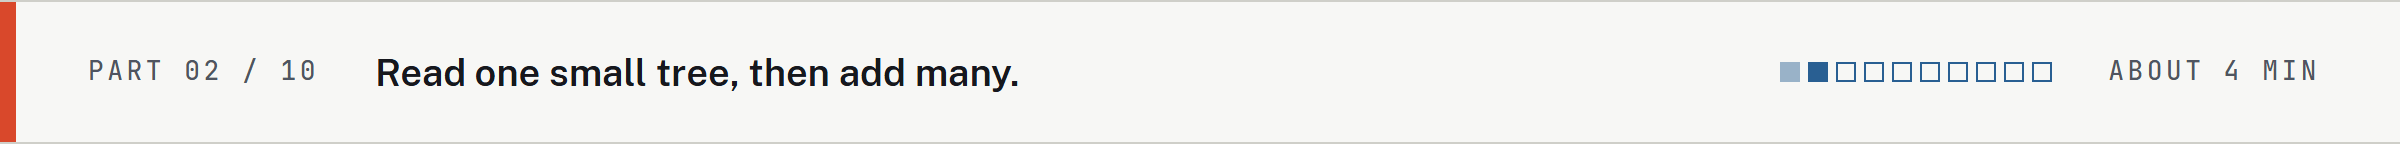

# One Tree, Then Many

A **decision tree** sorts rows with yes-or-no questions.
Each question compares one input with one number, and the rows that reach the same end, a **leaf**, get the same score.

One tree is easier to read on two inputs than on many, so this part uses the two axes of Chapter 3's risk map.

Q. What does a tree three questions deep ask of leverage and profitability?

In [5]:
def trees(params: dict, rounds: int, seed: int = SEED, **more) -> XGBClassifier:
    """A boosted tree model of `rounds` trees, fitted on one thread."""
    return XGBClassifier(n_estimators=rounds, n_jobs=1, random_state=seed, **params, **more)


TWO = ["liabilities_to_assets", "roa"]
SHOWN = (1, 10, 200)  # the round counts Exhibit 1 draws

prepare_two, *_ = fit_prepare(train_last, TWO, impute=False)
small = trees({"max_depth": 3, "learning_rate": 0.1}, max(SHOWN))
small.fit(prepare_two(train_last), train_last["target"])

first = small.get_booster().trees_to_dataframe().query("Tree == 0")
questions = first.loc[first["Feature"] != "Leaf", ["Node", "Feature", "Split", "Yes", "No"]]
# The reading names the first question. Checked here.
assert questions["Feature"].iloc[0] == "liabilities_to_assets"

store.put("first_split", questions["Split"].iloc[0])
store.put("n_leaves", int((first["Feature"] == "Leaf").sum()))

questions.round(3)

,Node,Feature,Split,Yes,No
0,0,liabilities_to_assets,0.754,0-1,0-2
1,1,roa,0.011,0-3,0-4
2,2,roa,0.036,0-5,0-6
3,3,liabilities_to_assets,0.310,0-7,0-8
4,4,roa,0.039,0-9,0-10
5,5,roa,-0.261,0-11,0-12
6,6,liabilities_to_assets,2.481,0-13,0-14


**Reading.** The first question is whether liabilities are below 0.75 of assets.
Each row answers three questions and lands in one of 8 leaves, so one tree can give only 8 different scores.

Every model in this chapter is fitted on one thread, so that its scores do not depend on how many cores the machine has.

**Boosting** adds trees one at a time.
Each new tree is fitted to what the trees before it still get wrong, and only a fraction of it, the learning rate, is added.

Q. What does the model look like after one tree, after ten, and after two hundred?

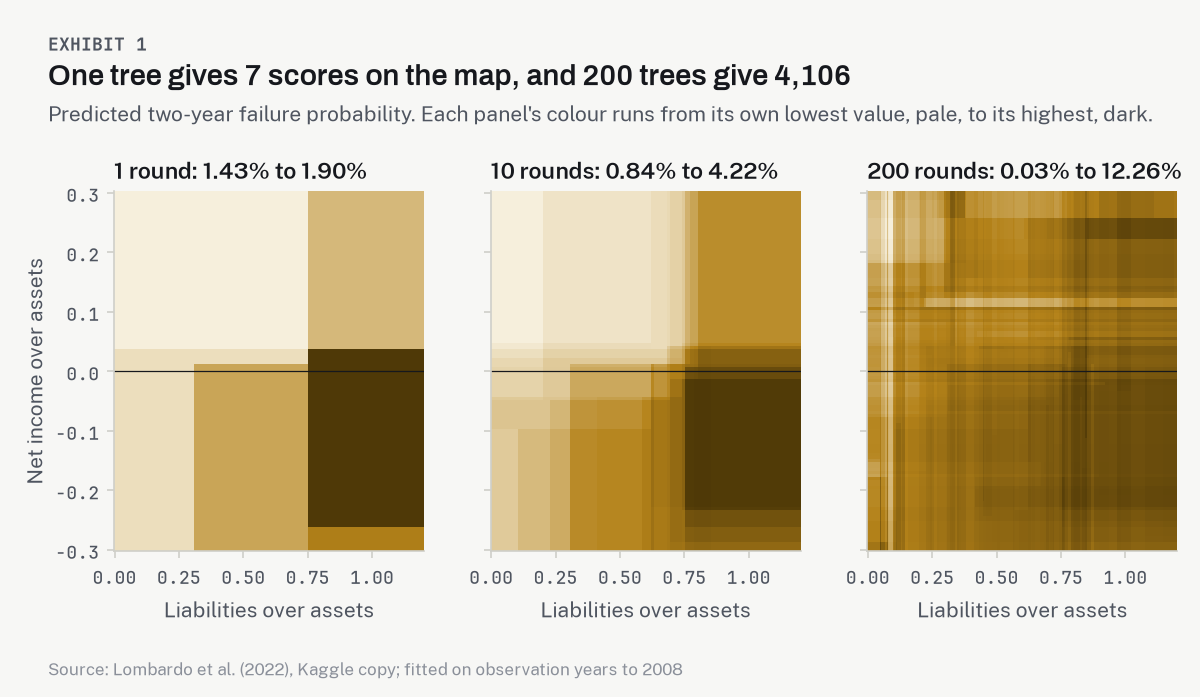

In [6]:
MAP = {"liabilities_to_assets": (0.0, 1.2), "roa": (-0.3, 0.3)}  # the frame of Chapter 3's risk map
across = np.linspace(*MAP["liabilities_to_assets"], 241)
up = np.linspace(*MAP["roa"], 121)
grid = prepare_two(
    pd.DataFrame(
        {"liabilities_to_assets": np.tile(across, len(up)), "roa": np.repeat(up, len(across))}
    )
)
ramp = LinearSegmentedColormap.from_list("ramp", ["#F6EFDC", TREES, "#4F3907"])
inputs_last = prepare_two(valid_last)

fig, axes = plt.subplots(1, len(SHOWN), figsize=(viz.EXHIBIT_WIDTH_IN, 3.3), sharey=True)
levels, small_auc = {}, {}
for ax, rounds in zip(axes, SHOWN):
    # iteration_range=(0, k) asks the fitted model for the sum of its first k trees only.
    surface = small.predict_proba(grid, iteration_range=(0, rounds))[:, 1]
    held_out = small.predict_proba(inputs_last, iteration_range=(0, rounds))[:, 1]
    levels[rounds] = len(np.unique(surface))
    small_auc[rounds] = roc_auc_score(valid_last["target"], held_out)
    ax.pcolormesh(across, up, surface.reshape(len(up), len(across)), cmap=ramp,
                  norm=LogNorm(surface.min(), surface.max()), shading="nearest", rasterized=True)  # fmt: skip
    ax.axhline(0, color=viz.INK, linewidth=0.6)
    ax.set_title(
        f"{rounds} round{'s' if rounds > 1 else ''}: {surface.min():.2%} to {surface.max():.2%}"
    )
    ax.set_xlabel("Liabilities over assets")
    ax.grid(visible=False)
axes[0].set_ylabel("Net income over assets")

# The reading says more rounds are not always better. Checked here.
assert small_auc[SHOWN[1]] > small_auc[SHOWN[2]]
for rounds in SHOWN:
    store.put(f"small_auc_{rounds}", small_auc[rounds])
store.put("leaves_on_map", levels[SHOWN[0]])

viz.exhibit(
    fig,
    f"One tree gives {levels[SHOWN[0]]} scores on the map, and {SHOWN[-1]} trees give "
    f"{levels[SHOWN[-1]]:,}",
    "Predicted two-year failure probability. Each panel's colour runs from its own lowest value, "
    "pale, to its highest, dark.",
    f"{SOURCE}; fitted on observation years to {train_last['year'].max()}",
)

**Reading.** In Exhibit 1 one tree cuts the map into rectangles, one for each of the 7 leaves that reach it.
Ten trees make a staircase that darkens towards the corner Chapter 3 found, where high leverage meets losses.

Two hundred trees add fine stripes, and a stripe a few firms wide is as likely noise as risk.
So more rounds are not always better.

On the validation year of the last fold the three models rank at 0.763, 0.770, and 0.749.

**Check.** A tree three questions deep has at most how many leaves? And why can ten such trees give more scores than ten times that?

<details>
<summary>Show the answer</summary>

Eight: each question splits a group in two, and two times two times two is eight.
Ten trees are added together, so a row's score depends on the leaf it reaches in every one of them, and the combinations are many more than the leaves.

</details>

**Next, what to do about failures being rare.**

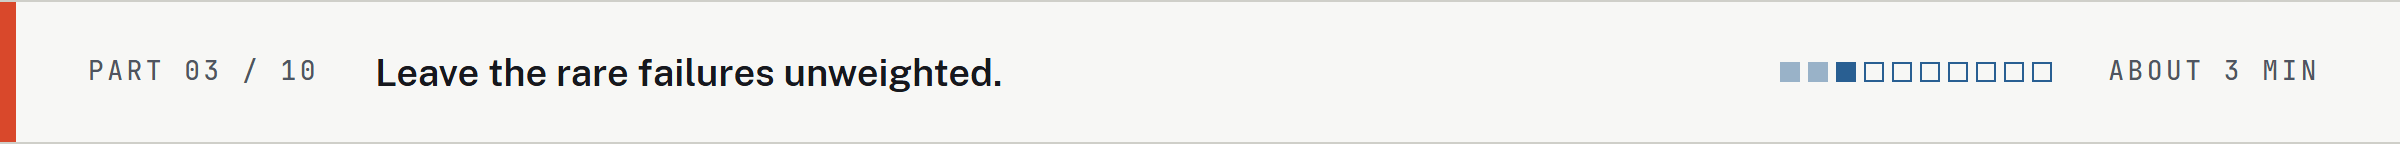

# Imbalance Without Tricks

Failures are rare, and a common reaction is to make each one count for more in the fit.
The setting is called `scale_pos_weight`, and its usual value is the number of survivors for each failure.

The weight changes what the model is told about how common failure is.
Whether that helps depends on what the score is for.

Every model from here on is scored the way Chapter 4 scored the logistic regression: walked forward through the seven folds.
The function that does it is short enough to read in full.

In [7]:
# taught: corp_default.evaluate.walk_forward_oof
def walk_forward_oof(
    fit_predict: Callable[[pd.DataFrame, pd.DataFrame], np.ndarray],
    frame: pd.DataFrame,
    folds: list[Fold],
) -> pd.DataFrame:
    """Score every validation row with a model fitted on its fold's training rows only.

    fit_predict(train_rows, valid_rows) returns one score per validation row, higher is riskier.
    pct is the score's percentile within its own year.
    """
    parts = []
    for fold in folds:
        train, valid = frame.loc[fold.train], frame.loc[fold.valid]
        scores = np.asarray(fit_predict(train, valid))
        if len(scores) != len(valid):
            raise ValueError(
                f"fit_predict returned {len(scores)} scores for {len(valid)} rows in fold {fold.year}"
            )
        parts.append(valid[[*KEYS, "target"]].assign(score=scores))
    oof = pd.concat(parts, ignore_index=True)
    return oof.assign(pct=within_year_percentile(oof["score"], oof["year"]))

**Reading.** For each fold the function hands `fit_predict` the training rows and the validation rows, and keeps one score for each validation row.
Every model below is a `fit_predict`.

**Predict 1.** In the last fold the weight makes each failure count as much as 64 survivors. Will the weighted model rank the validation rows better, worse, or about the same?

Q. What does the weight do to the ranking, and to the probabilities?

In [8]:
START = {"max_depth": 3, "learning_rate": 0.05, "subsample": 0.8, "colsample_bytree": 0.7}
START_ROUNDS = 200  # a plain starting configuration, before any tuning


def tree_scores(params: dict, columns: list[str], rounds: int, **more) -> Callable:
    """A fit_predict for walk_forward_oof: boosted trees on `columns`, tails clipped at training bounds."""

    def fit_predict(train: pd.DataFrame, valid: pd.DataFrame) -> np.ndarray:
        prepare, *_ = fit_prepare(train, columns, impute=False)
        model = trees(params, rounds, **more).fit(prepare(train), train["target"])
        return model.predict_proba(prepare(valid))[:, 1]

    return fit_predict


def survivors_per_failure(rows: pd.DataFrame) -> float:
    return (rows["target"] == 0).sum() / rows["target"].sum()


def weighted(train: pd.DataFrame, valid: pd.DataFrame) -> np.ndarray:
    """The starting configuration with each failure weighted by the survivors per failure."""
    weight = survivors_per_failure(train)
    return tree_scores(START, RATIOS, START_ROUNDS, scale_pos_weight=weight)(train, valid)


by_weight = {
    "No weight": walk_forward_oof(tree_scores(START, RATIOS, START_ROUNDS), dev, folds),
    "Failures weighted": walk_forward_oof(weighted, dev, folds),
}
weight_step = paired_table(by_weight, list(by_weight)).iloc[0]
# The reading says the weighted model ranks no better. Checked here.
assert weight_step["roc_auc_diff_lo"] < 0

compare = pd.DataFrame(
    {
        name: {
            "ROC-AUC": roc_auc_score(oof["target"], oof["pct"]),
            "average precision": average_precision_score(oof["target"], oof["pct"]),
            "mean predicted probability": oof["score"].mean(),
            "share that fail": oof["target"].mean(),
        }
        for name, oof in by_weight.items()
    }
).T

store.put("weight_last", survivors_per_failure(train_last))
store.put("weight_step", weight_step["roc_auc_diff"])
store.put("weight_step_low", weight_step["roc_auc_diff_lo"])
store.put("weight_step_high", weight_step["roc_auc_diff_hi"])
store.put("weighted_mean", compare.loc["Failures weighted", "mean predicted probability"])
store.put("plain_mean", compare.loc["No weight", "mean predicted probability"])
store.put("oof_base_rate", compare.loc["No weight", "share that fail"])
# The reading says failures grew more common after the training years. Checked here.
assert (
    np.mean([dev.loc[fold.train, "target"].mean() for fold in folds])
    < dev.loc[np.concatenate([fold.valid for fold in folds]), "target"].mean()
)

compare.round(4)

,ROC-AUC,average precision,mean predicted probability,share that fail
No weight,0.7524,0.0618,0.0114,0.0191
Failures weighted,0.7419,0.0591,0.2783,0.0191


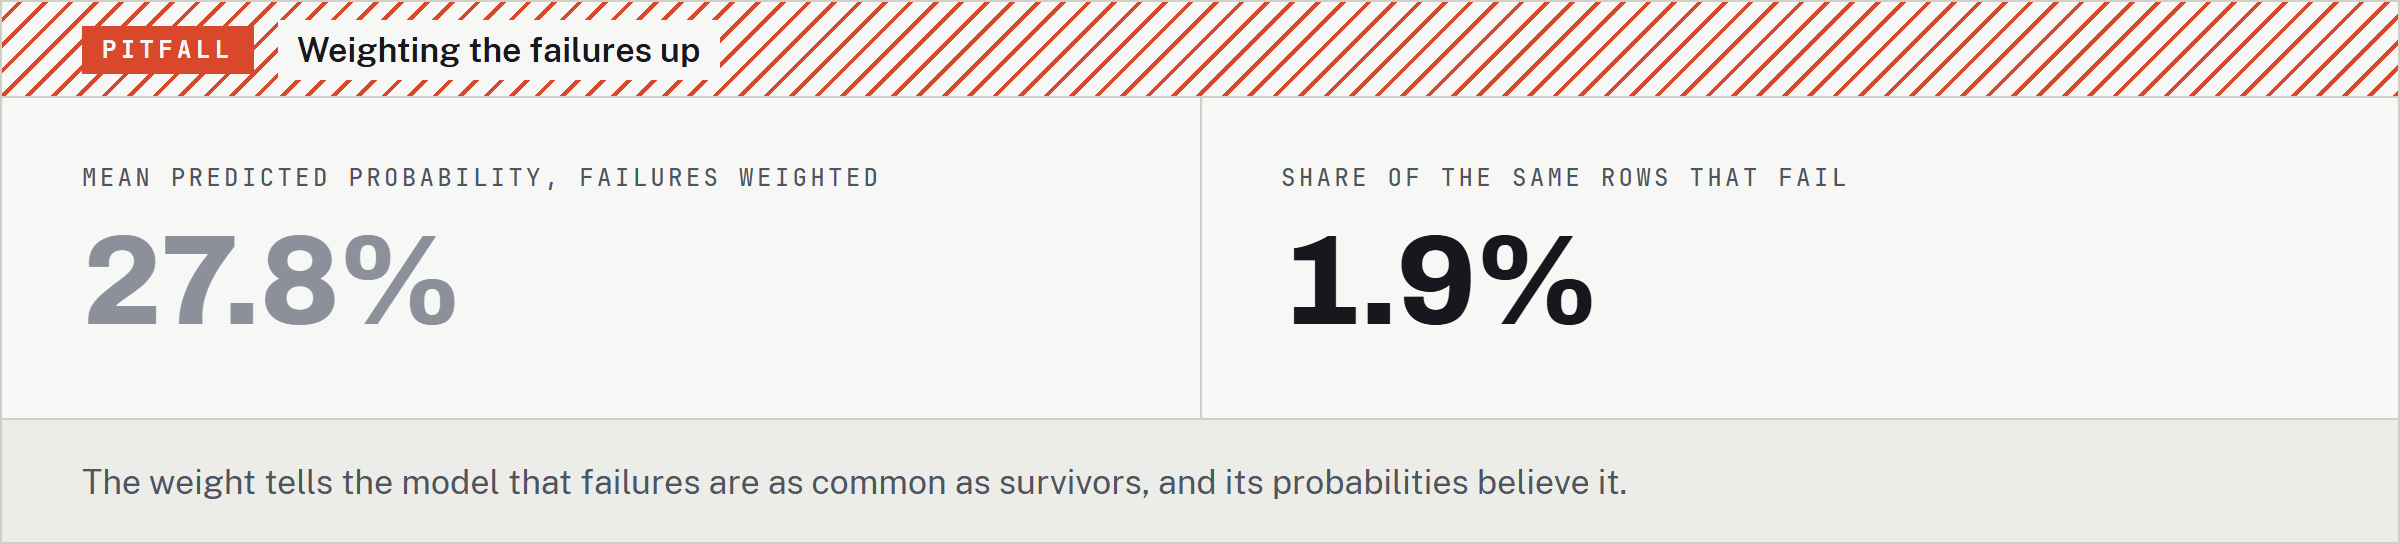

**Reading.** The weighted model ranks no better: the paired difference in ROC-AUC is -0.011, with an interval from -0.022 to 0.001.
That answers Predict 1.

Its probabilities are another matter: it says 28% on average, of rows that fail at 1.9%.
A ranking survives that, and a probability of default does not.

The unweighted model is off too, at 1.1%, because failures grew more common after its training years.
Turning a score into a probability is the work of Chapter 7, and no model in this casebook weights its failures.

**Next, how far to trust one validation score.**

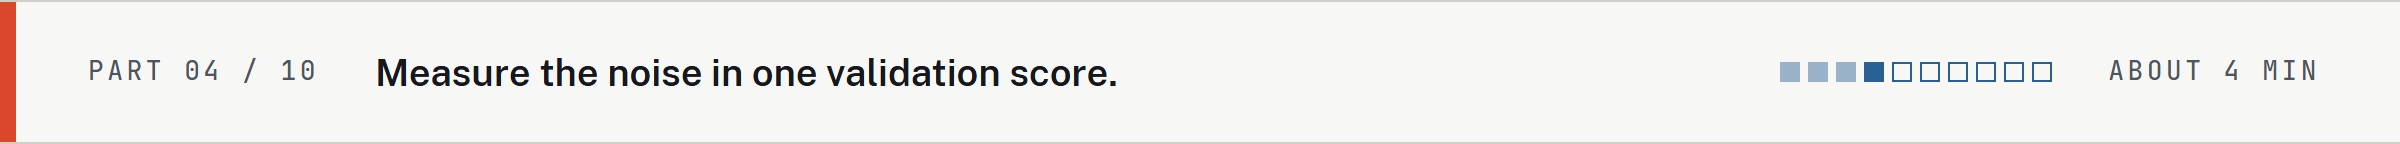

# How Noisy Is a Validation Score

Tuning means fitting many configurations and keeping the one that scores best.
That only works if the difference between two scores is larger than the noise in each.

One source of noise can be measured exactly.
The starting configuration shows each tree a random 80% of the rows, and the **seed** decides which.

**Predict 2.** Fit the same configuration 20 times on the same rows, changing only the seed. Between the unluckiest seed and the luckiest, does average precision on one validation year move by a twentieth of its value, or by a quarter?

Q. How far does average precision move when only the seed changes?

In [9]:
N_SEEDS = 20


def on_last_fold(params: dict, seed: int = SEED) -> float:
    """Average precision on the last fold's validation year, at the starting round count."""
    score = tree_scores(params, RATIOS, START_ROUNDS, seed=seed)(train_last, valid_last)
    return average_precision_score(valid_last["target"], score)


# One fit on each core at a time. Each fit still runs on one thread, so its scores are those of a fit run alone.
with ThreadPoolExecutor(CORES) as pool:
    by_seed = pd.Series(list(pool.map(lambda seed: on_last_fold(START, seed), range(N_SEEDS))))

store.put("n_seeds", N_SEEDS)
store.put("start_subsample", START["subsample"])
store.put("seed_sd", by_seed.std())
store.put("seed_low", by_seed.min())
store.put("seed_high", by_seed.max())
store.put("seed_swing", (by_seed.max() - by_seed.min()) / by_seed.mean())

by_seed.describe().round(4)

count    20.0000
mean      0.0727
std       0.0049
min       0.0641
25%       0.0701
50%       0.0710
75%       0.0762
max       0.0827
dtype: float64

**Reading.** From the unluckiest seed to the luckiest, average precision runs from 0.064 to 0.083, a swing of 26% of its mean.
That answers Predict 2.

The standard deviation is 0.0049: call it the noise of one score.

A search draws configurations at random from a **search space**, the values each setting may take.

| Setting | What it controls |
| --- | --- |
| `max_depth` | The depth of each tree |
| `learning_rate` | The fraction of each tree that is added |
| `min_child_weight` | How much data a leaf must hold |
| `subsample` | The share of rows each tree sees |
| `colsample_bytree` | The share of columns each tree sees |
| `reg_lambda` | A penalty that shrinks the score of each leaf |

Q. How far apart are 30 configurations on the same fold, with the same seed?

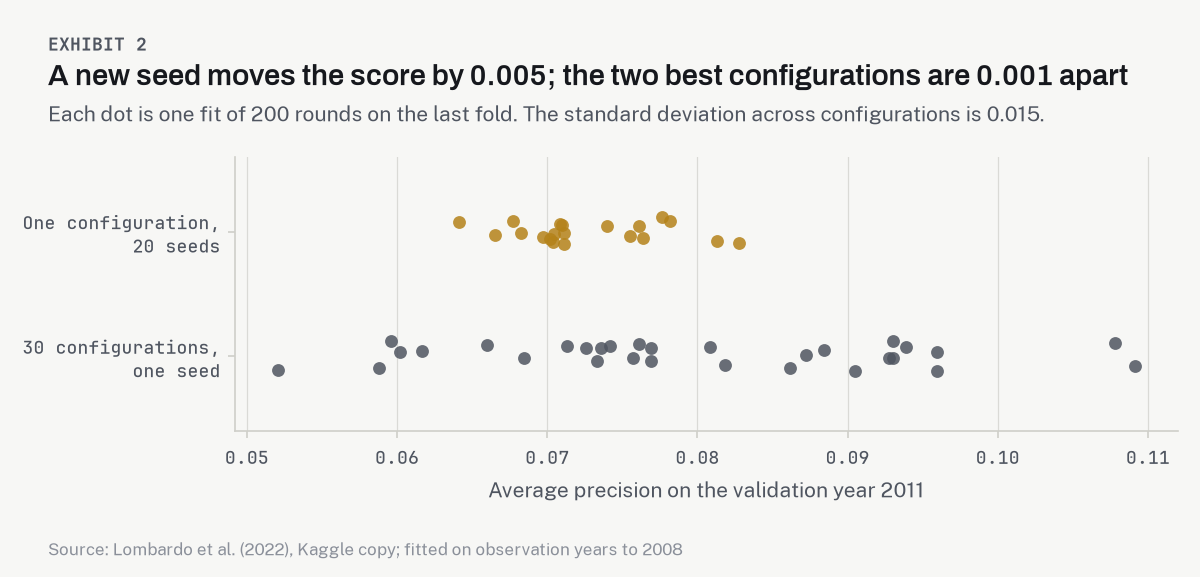

In [10]:
SPACE = {
    "max_depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.02, 0.03, 0.05, 0.1],
    "min_child_weight": [1, 5, 10, 20, 50],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.5, 0.7, 1.0],
    "reg_lambda": [1, 5, 10, 30],
}
N_CONFIGS = 30
configs = list(ParameterSampler(SPACE, n_iter=N_CONFIGS, random_state=SEED))

with ThreadPoolExecutor(CORES) as pool:
    by_config = pd.Series(list(pool.map(on_last_fold, configs)))

top_gap = by_config.nlargest(2).iloc[0] - by_config.nlargest(2).iloc[1]
# The reading says the two best configurations are closer than the noise of a seed. Checked here.
assert top_gap < by_seed.std() < by_config.std()

store.put("n_configs", N_CONFIGS)
store.put("config_sd", by_config.std())
store.put("top_gap", top_gap)

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 2.5))
jitter = np.random.default_rng(SEED)
rows = [
    (f"{N_CONFIGS} configurations,\none seed", by_config, viz.SLATE),
    (f"One configuration,\n{N_SEEDS} seeds", by_seed, TREES),
]
for y_at, (label, values, color) in enumerate(rows):
    ax.scatter(values, y_at + jitter.uniform(-0.13, 0.13, len(values)), s=38, color=color,
               alpha=0.85, linewidths=0)  # fmt: skip
ax.set_yticks(range(len(rows)), [label for label, _, _ in rows])
ax.set_ylim(-0.6, len(rows) - 0.4)
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Average precision on the validation year {last.year}")
viz.exhibit(
    fig,
    f"A new seed moves the score by {by_seed.std():.3f}; the two best configurations are "
    f"{top_gap:.3f} apart",
    f"Each dot is one fit of {START_ROUNDS} rounds on the last fold. The standard deviation across "
    f"configurations is {by_config.std():.3f}.",
    f"{SOURCE}; fitted on observation years to {train_last['year'].max()}",
)

**Reading.** In Exhibit 2 the configurations spread wider than the seeds, with a standard deviation of 0.015 against 0.005.
So one window can tell a good configuration from a poor one.

It cannot tell the best from the second best: they are 0.0013 apart, less than the noise of a seed.
Picking the top dot on one window is partly picking luck.

**Next, a search that averages the luck away.**

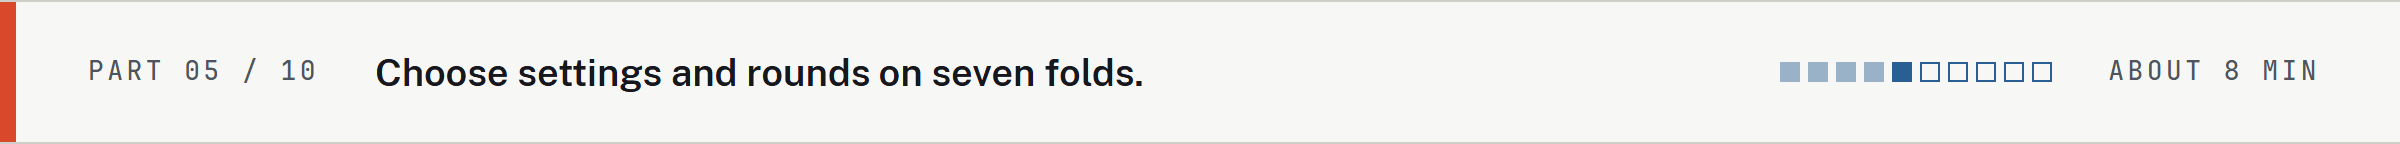

# Tuning on a Walk-Forward

The remedy is the one Chapter 4 built: score every configuration on all seven folds.

The rule is written before the result.
The search keeps the configuration and the number of rounds with the highest mean average precision over the seven folds, each fold counting the same.

The number of rounds needs care.
The usual shortcut, **early stopping**, watches the score on the validation rows and stops adding trees when it peaks, so each fold gets the round count that suits its own validation rows best.

There is a way round it.
A model fitted to 400 rounds contains the model of every smaller count, and `iteration_range` reads each one out.

So each configuration is fitted once on each fold and scored at 11 round counts.
One count then serves all seven folds, chosen with the configuration by the same rule.

Q. How is one configuration scored on one fold, at every round count?

In [11]:
CUTOFFS = [1, 2, 5, 10, 25, 50, 100, 150, 200, 300, 400]


def score_at_cutoffs(number: int, columns: list[str], fold: Fold) -> list[dict]:
    """Fit configuration `number` once on the fold, then score its validation year at each cut-off."""
    train, valid = dev.loc[fold.train], dev.loc[fold.valid]
    prepare, *_ = fit_prepare(train, columns, impute=False)
    model = trees(configs[number], max(CUTOFFS)).fit(prepare(train), train["target"])
    inputs, rows = prepare(valid), []
    for rounds in CUTOFFS:
        score = model.predict_proba(inputs, iteration_range=(0, rounds))[:, 1]
        rows.append(
            {
                "config": number,
                "fold": fold.year,
                "rounds": rounds,
                "ap": average_precision_score(valid["target"], score),
                "roc_auc": roc_auc_score(valid["target"], score),
            }
        )
    return rows


def search(columns: list[str]) -> pd.DataFrame:
    """Every configuration on every fold at every cut-off, one row for each."""
    jobs = [(number, fold) for number in range(N_CONFIGS) for fold in folds]
    with ThreadPoolExecutor(CORES) as pool:
        scored = pool.map(lambda job: score_at_cutoffs(job[0], columns, job[1]), jobs)
        return pd.DataFrame([row for rows in scored for row in rows])


def choose(table: pd.DataFrame) -> tuple[int, int]:
    """The configuration and round count with the highest mean average precision over the folds."""
    mean = table.groupby(["config", "rounds"])["ap"].mean()
    number, rounds = mean.idxmax()
    return int(number), int(rounds)


store.put("max_rounds", max(CUTOFFS))
store.put("n_cutoffs", len(CUTOFFS))
store.put("n_search_fits", N_CONFIGS * len(folds))

**Reading.** `score_at_cutoffs` is one fold of `walk_forward_oof` with one change: it scores the validation year 11 times, once at each count.

The next cell fits 210 models and takes a few minutes.

Q. Which configuration and which round count does the rule choose?

In [12]:
snapshot_search = search(RATIOS)
best, ROUNDS = choose(snapshot_search)
FROZEN = configs[best]
# The reading says the choice is the shallowest tree and the slowest learning rate on offer. Checked here.
assert FROZEN["max_depth"] == min(SPACE["max_depth"])
assert FROZEN["learning_rate"] == min(SPACE["learning_rate"])

mean_ap = snapshot_search.groupby(["config", "rounds"])["ap"].mean()
# One row for each round count, one column for each configuration.
by_rounds = mean_ap.unstack("config")
leaders = (
    pd.DataFrame(configs)
    .assign(rounds=by_rounds.idxmax(), mean_ap=by_rounds.max())
    .sort_values("mean_ap", ascending=False)
)

store.put("frozen_depth", FROZEN["max_depth"])
store.put("frozen_rate", FROZEN["learning_rate"])
store.put("rounds", ROUNDS)
store.put("chosen_mean_ap", mean_ap.max())
store.put("leaders_shown", 8)
store.put("leaders_within", leaders["mean_ap"].iloc[0] - leaders["mean_ap"].iloc[7])

leaders.head(8).round(4)

,subsample,reg_lambda,min_child_weight,max_depth,learning_rate,colsample_bytree,rounds,mean_ap
25,0.6,30,10,2,0.02,1.0,200,0.0795
17,0.8,30,1,4,0.02,0.5,100,0.0780
11,0.6,10,10,2,0.03,0.5,200,0.0778
26,0.6,5,5,2,0.02,0.7,300,0.0775
24,0.6,30,10,4,0.03,1.0,100,0.0774
22,0.6,5,5,2,0.03,0.7,100,0.0765
3,0.8,30,10,3,0.02,0.7,150,0.0754
8,0.6,30,1,3,0.10,0.7,25,0.0742


**Reading.** The rule chooses trees 2 questions deep, a learning rate of 0.02, and 200 rounds, for a mean average precision of 0.0795.
The table lists each configuration at its own best round count, and the top 8 lie within 0.0054 of each other.

So the search finds a neighbourhood and not a point: shallow trees that learn slowly.
The choice is the shallowest tree and the slowest learning rate the space offers, so the best model may lie beyond its edge, which Your Turn takes up.

Q. How does average precision move as rounds are added?

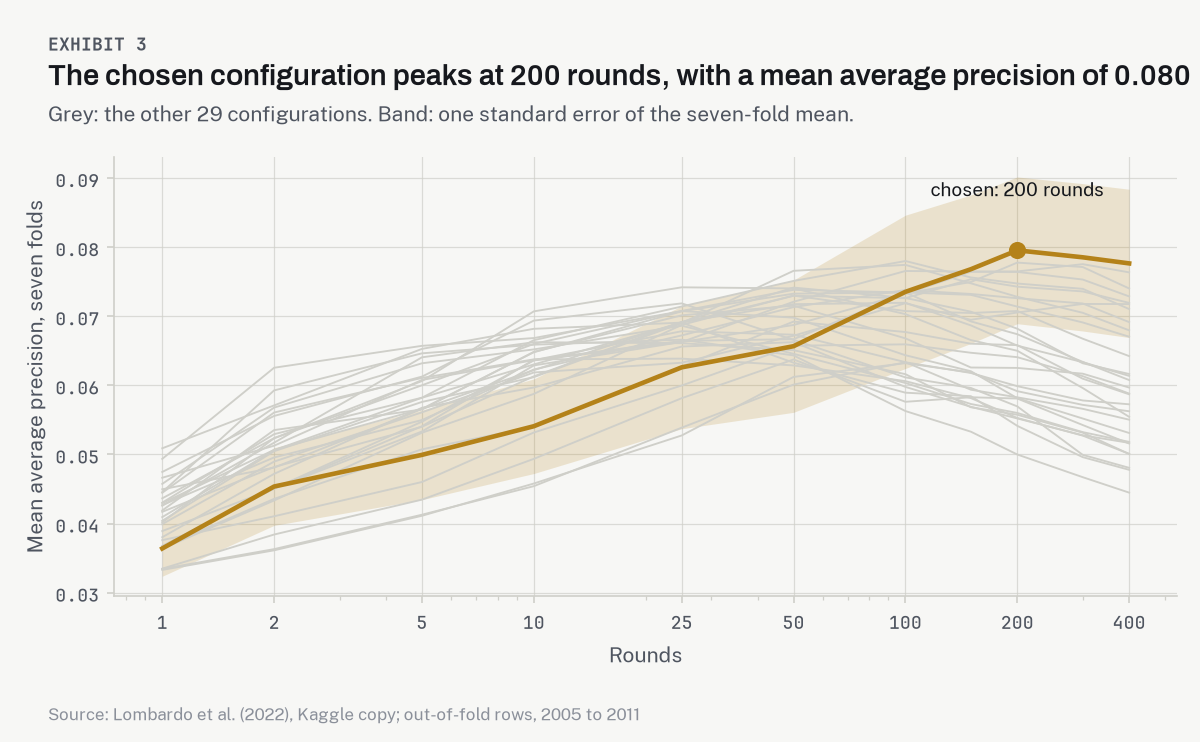

In [13]:
standard_error = snapshot_search.groupby(["config", "rounds"])["ap"].sem().unstack("config")[best]
peak_rounds = by_rounds.idxmax()
rates = pd.Series([params["learning_rate"] for params in configs])
# The reading says the fast learners peak early. Checked here.
assert (
    peak_rounds[rates == max(SPACE["learning_rate"])].max()
    < peak_rounds[rates == min(SPACE["learning_rate"])].min()
)

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.6))
ax.plot(by_rounds.index, by_rounds.drop(columns=best), color=viz.RULE, linewidth=0.9)
ax.fill_between(by_rounds.index, by_rounds[best] - standard_error, by_rounds[best] + standard_error,
                color=TREES, alpha=0.18, linewidth=0)  # fmt: skip
ax.plot(by_rounds.index, by_rounds[best], color=TREES, linewidth=2.2)
ax.scatter([ROUNDS], [by_rounds.loc[ROUNDS, best]], s=52, color=TREES, zorder=3)
ax.annotate(f"chosen: {ROUNDS} rounds", (ROUNDS, by_rounds.loc[ROUNDS, best]), xytext=(0, 26),
            textcoords="offset points", ha="center", size=9)  # fmt: skip
viz.log_axis(ax, "x")
ax.set_xticks([1, 2, 5, 10, 25, 50, 100, 200, 400])
ax.set_xlabel("Rounds")
ax.set_ylabel("Mean average precision, seven folds")
viz.exhibit(
    fig,
    f"The chosen configuration peaks at {ROUNDS} rounds, with a mean average precision of "
    f"{mean_ap.max():.3f}",
    f"Grey: the other {N_CONFIGS - 1} configurations. Band: one standard error of the seven-fold mean.",
    OOF_SOURCE,
)

**Reading.** In Exhibit 3 every configuration rises and then falls as trees are added: past its peak a model is fitting noise.
The configurations with the fastest learning rate peak early and fall hard, and the chosen one climbs slowly to 200 rounds.

The band is wide because the folds differ: a year with more failures gives every model a higher average precision.
All configurations share that part of the spread, which is why they are compared on the same folds.

Q. What would a single validation window have chosen?

In [14]:
windows = []
for fold in folds:
    own = snapshot_search.loc[snapshot_search["fold"] == fold.year]
    winner = own.loc[own["ap"].idxmax()]
    same = (snapshot_search["config"] == winner["config"]) & (
        snapshot_search["rounds"] == winner["rounds"]
    )
    elsewhere = snapshot_search.loc[same & (snapshot_search["fold"] != fold.year), "ap"].mean()
    windows.append(
        {
            "window": fold.year,
            "config": int(winner["config"]),
            "rounds": int(winner["rounds"]),
            "on its own window": winner["ap"],
            "on the other folds": elsewhere,
        }
    )
windows = pd.DataFrame(windows).set_index("window")
SHORT = 50  # rounds

store.put("n_winners", windows["config"].nunique())
store.put("windows_agree", int(((windows["config"] == best) & (windows["rounds"] == ROUNDS)).sum()))
store.put("winner_own", windows["on its own window"].mean())
store.put("winner_elsewhere", windows["on the other folds"].mean())
store.put("short_rounds", SHORT)
store.put("short_winners", int((windows["rounds"] <= SHORT).sum()))

windows.round(4)

,config,rounds,on its own window,on the other folds
window,,,,
2005,23,25,0.0774,0.0677
2006,8,25,0.1228,0.0661
2007,6,50,0.1241,0.0630
2008,15,50,0.0635,0.0608
2009,13,150,0.0599,0.0722
2010,14,25,0.0639,0.0732
2011,25,200,0.1091,0.0746


![Pitfall: Choosing on one validation window. Average precision of each window's winner, on its window: 0.089. The same 7 winners, on the folds that did not choose them: 0.068. The best of many scores on one window is partly luck, and the luck stays behind in that window.](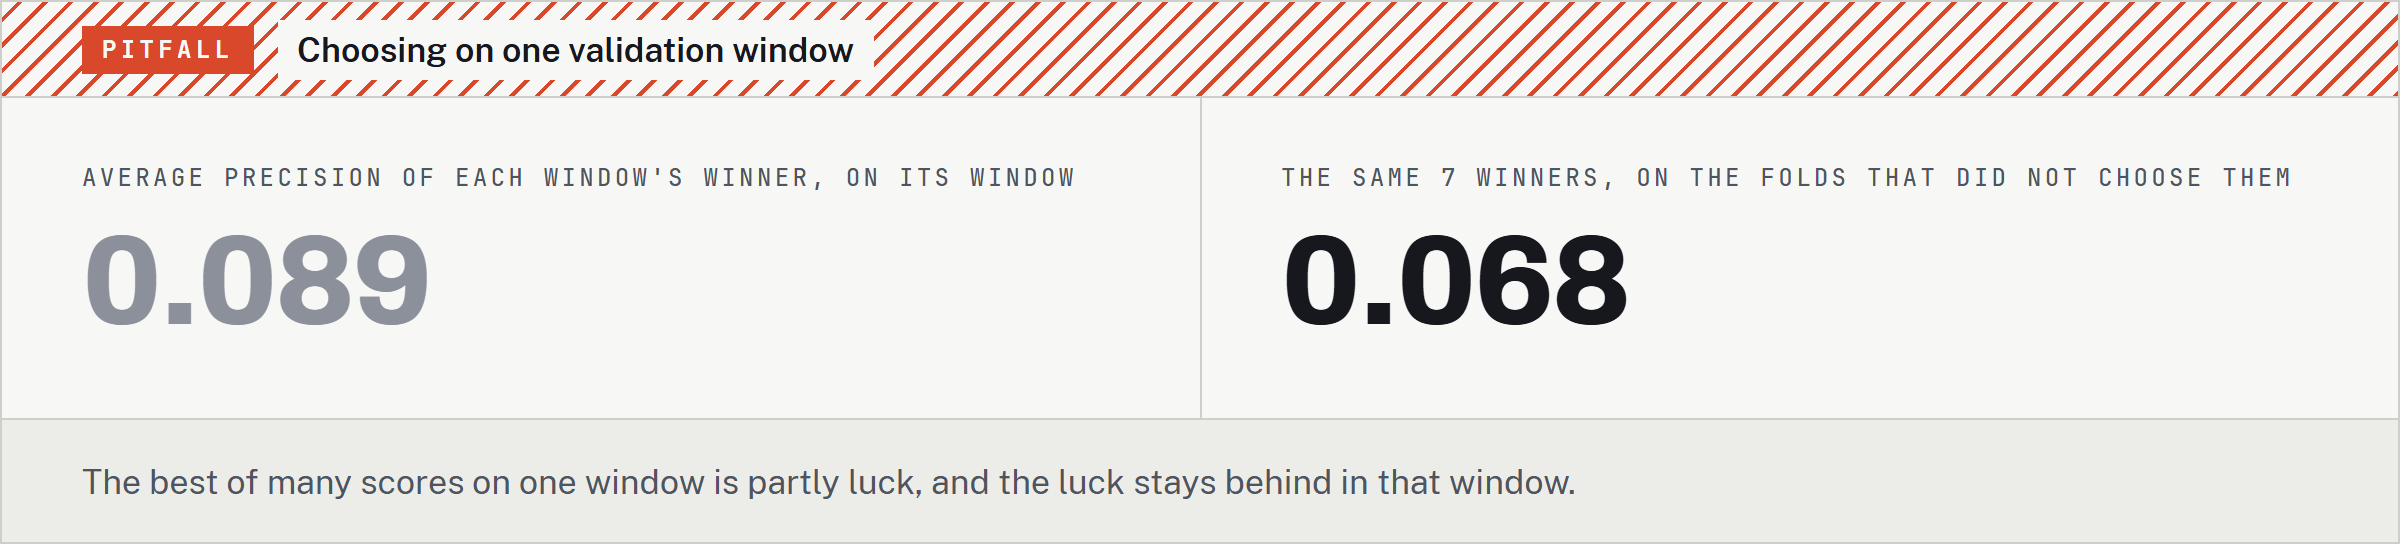)

**Reading.** Each row takes one fold as the only validation window and crowns the best score on it.
The 7 windows crown 7 different configurations, and the number that agree with the seven-fold choice is 1.

On their own windows the winners average 0.089, and on the folds that did not choose them, 0.068.
Both averages give every fold the same weight, so the gap is not one year being easier: it is the luck of winning.

A single window also likes a short model.
Of the 7 winners, 5 stop at 50 rounds or fewer, where the seven-fold choice runs to 200.

Q. Is the seven-fold choice flattered too?

In [15]:
held_out = []
for fold in folds:
    number, rounds = choose(snapshot_search.loc[snapshot_search["fold"] != fold.year])
    year = fold.year
    scored = snapshot_search.query("config == @number and rounds == @rounds and fold == @year")
    held_out.append(scored["ap"].iloc[0])
held_out_ap = float(np.mean(held_out))

store.put("held_out_ap", held_out_ap)
store.put(
    "flattery_share",
    (mean_ap.max() - held_out_ap)
    / (windows["on its own window"].mean() - windows["on the other folds"].mean()),
)

pd.Series({"chosen on seven folds, scored on the same seven": mean_ap.max(),
           "chosen on six folds, scored on the seventh": held_out_ap}).round(4)  # fmt: skip

chosen on seven folds, scored on the same seven    0.0795
chosen on six folds, scored on the seventh         0.0751
dtype: float64

**Reading.** Choosing on six folds and scoring on the seventh, each fold in turn, gives 0.0751 against 0.0795.
So some flattery is left in the seven-fold choice, 21% of what a single window carried.

That is why the holdout stays sealed.
The only score no choice has touched is the one Chapter 7 opens.

**Check.** Early stopping gives each fold its own round count. Why is the mean of those seven scores too high?

<details>
<summary>Show the answer</summary>

Each fold's count is the one that scored best on that fold's own validation rows, so each of the seven scores is a best of many.
One count for all seven folds, chosen by their mean, is a best of many only once, and by much less.

</details>

**Next, the chosen configuration on the ratios.**

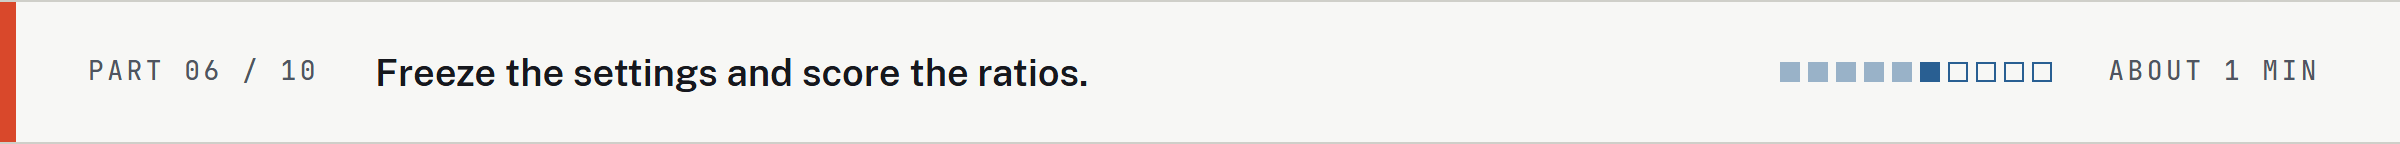

# The Snapshot Model

The configuration is now **frozen**: trees 2 questions deep, a learning rate of 0.02, and 200 rounds.

On the ratios alone it is the **snapshot model**: it sees each firm-year as one photograph, with nothing of the years before.
It is rung four of the ladder, the inputs of rung three with trees in place of a weighted sum.

Q. What do trees add to the same ratios?

In [16]:
ladder = {
    name: part.drop(columns="model").reset_index(drop=True)
    for name, part in earlier.groupby("model", sort=False)
}
ladder["All ratios, trees"] = walk_forward_oof(tree_scores(FROZEN, RATIOS, ROUNDS), dev, folds)


def ap_by_fold(oof: pd.DataFrame) -> pd.Series:
    """Average precision within each validation year."""
    return oof.groupby("year").apply(
        lambda rows: average_precision_score(rows["target"], rows["score"])
    )


# The frozen model is the one the search scored: fold by fold its average precision is the search's.
searched = snapshot_search.query("config == @best and rounds == @ROUNDS").set_index("fold")["ap"]
assert np.allclose(ap_by_fold(ladder["All ratios, trees"]), searched)

tree_step = paired_table(ladder, ["All ratios, logistic", "All ratios, trees"]).iloc[0]
# The reading says the step is clear of zero on both measures. Checked here.
assert tree_step["roc_auc_diff_lo"] > 0 and tree_step["ap_diff_lo"] > 0

store.put("tree_step", tree_step["roc_auc_diff"])
store.put("tree_step_low", tree_step["roc_auc_diff_lo"])
store.put("tree_step_high", tree_step["roc_auc_diff_hi"])
store.put("tree_step_ap", tree_step["ap_diff"])

tree_step.to_frame().T.set_index("model").drop(columns=["against", "usable"]).astype(float).round(4)

,roc_auc_diff,roc_auc_diff_lo,roc_auc_diff_hi,ap_diff,ap_diff_lo,ap_diff_hi
model,,,,,,
"All ratios, trees",0.0258,0.0103,0.0416,0.018,0.0083,0.0317


**Reading.** Trees add 0.026 of ROC-AUC to the same 24 ratios, with an interval from 0.010 to 0.042.
Average precision rises by 0.018, and both intervals stay above zero.

That is what non-linearity buys: the bends in Chapter 3's curves and the corner of its risk map, which a weighted sum cannot follow.

**Next, the years before the photograph.**

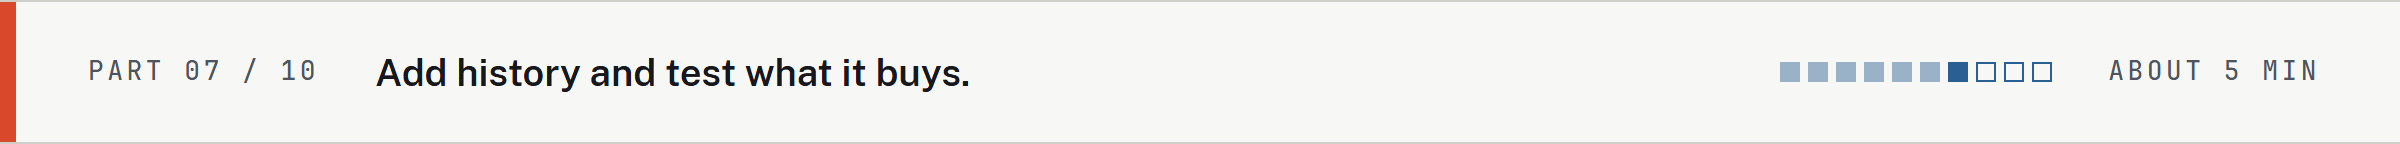

# Adding History

Chapter 3 showed failed firms decaying for years before their last filing, and built 21 columns to carry that: changes, growth, and past losses.
Rung five gives the frozen configuration those columns beside the ratios.

**Predict 3.** The snapshot model reads one year. With 21 columns of history beside it, by how much does the walk-forward ROC-AUC rise?

Q. What does history add to the snapshot model?

In [17]:
ladder["Plus history"] = walk_forward_oof(tree_scores(FROZEN, ALL, ROUNDS), dev, folds)
history_step = paired_table(ladder, ["All ratios, trees", "Plus history"]).iloc[0]
# The reading says ROC-AUC falls, with an interval below zero, and average precision is level. Checked here.
assert history_step["roc_auc_diff_hi"] < 0
assert history_step["ap_diff_lo"] < 0 < history_step["ap_diff_hi"]

store.put("history_step", history_step["roc_auc_diff"])
store.put("history_step_low", history_step["roc_auc_diff_lo"])
store.put("history_step_high", history_step["roc_auc_diff_hi"])
store.put("history_step_ap", history_step["ap_diff"])
store.put("history_step_ap_low", history_step["ap_diff_lo"])
store.put("history_step_ap_high", history_step["ap_diff_hi"])

history_step.to_frame().T.set_index("model").drop(columns=["against", "usable"]).astype(
    float
).round(4)

,roc_auc_diff,roc_auc_diff_lo,roc_auc_diff_hi,ap_diff,ap_diff_lo,ap_diff_hi
model,,,,,,
Plus history,-0.0259,-0.0417,-0.0109,-0.0035,-0.012,0.0046


**Reading.** It does not rise.
The difference in ROC-AUC is -0.026, with an interval from -0.042 to -0.011 that stays below zero, which answers Predict 3.

Average precision is level: its difference is -0.004, with an interval from -0.012 to 0.005.

The frozen configuration was chosen for the ratios, which may be unfair to a larger set of inputs.
So history gets a search of its own, another 210 fits.

Q. Does history do better with a configuration chosen for it?

In [18]:
history_search = search(ALL)
own_best, own_rounds = choose(history_search)
own_oof = walk_forward_oof(tree_scores(configs[own_best], ALL, own_rounds), dev, folds)
own_step = paired_table(
    {"All ratios, trees": ladder["All ratios, trees"], "History, own search": own_oof},
    ["All ratios, trees", "History, own search"],
).iloc[0]
# The reading says history still trails, with an interval below zero. Checked here.
assert own_step["roc_auc_diff_hi"] < 0

store.put("own_step", own_step["roc_auc_diff"])
store.put("own_step_low", own_step["roc_auc_diff_lo"])
store.put("own_step_high", own_step["roc_auc_diff_hi"])
store.put("own_depth", configs[own_best]["max_depth"])
store.put("own_rounds", own_rounds)

own_step.to_frame().T.set_index("model").drop(columns=["against", "usable"]).astype(float).round(4)

,roc_auc_diff,roc_auc_diff_lo,roc_auc_diff_hi,ap_diff,ap_diff_lo,ap_diff_hi
model,,,,,,
"History, own search",-0.0182,-0.0346,-0.0023,0.0014,-0.0075,0.0099


**Reading.** The search chooses trees 2 questions deep and 150 rounds, and history still trails the snapshot model.
The difference in ROC-AUC is -0.018, with an interval from -0.035 to -0.002, so the configuration is not the reason.

The two searches scored the same 30 configurations on the same folds, once without history and once with it.
That gives 30 paired comparisons in every fold.

Q. In which folds does history lose?

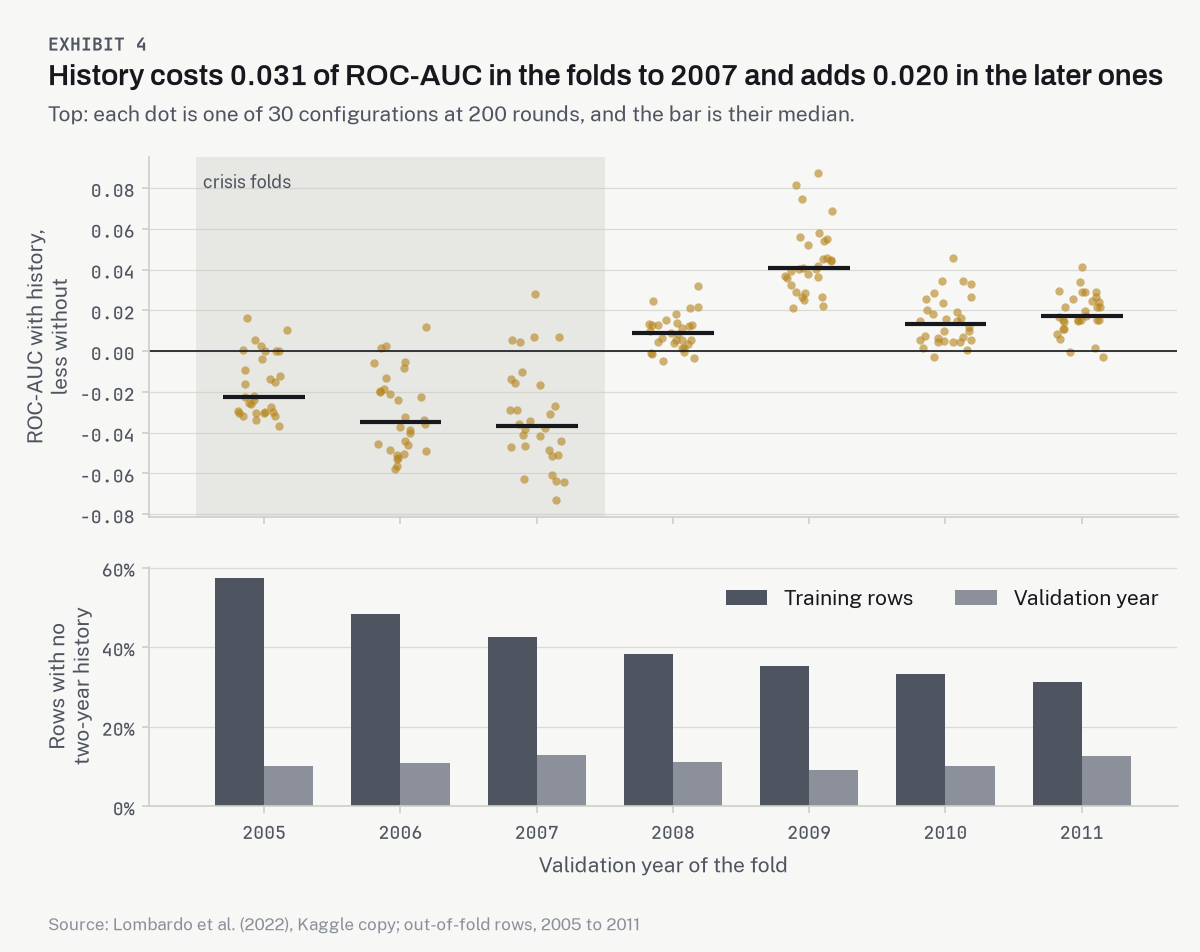

In [19]:
both = snapshot_search.merge(
    history_search, on=["config", "fold", "rounds"], suffixes=("_ratios", "_history")
)
both = both.loc[both["rounds"] == ROUNDS]
gaps = both.assign(gap=both["roc_auc_history"] - both["roc_auc_ratios"])
median_gap = gaps.groupby("fold")["gap"].median()
early, later = median_gap.loc[list(CRISIS_FOLDS)], median_gap.drop(index=list(CRISIS_FOLDS))
# The title and the reading say history loses in the early folds and gains in the later ones. Checked here.
assert (early < 0).all() and (later > 0).all()

# A row has no two-year history when its company filed nothing two years earlier.
no_history = dev["loss_2y_ago"].isna()
blank = pd.DataFrame(
    {
        "Training rows": [no_history.loc[fold.train].mean() for fold in folds],
        "Validation year": [no_history.loc[fold.valid].mean() for fold in folds],
    },
    index=[fold.year for fold in folds],
)
first_train = dev.loc[folds[0].train]
history_years = sorted(first_train.loc[~no_history.loc[folds[0].train], "year"].unique())

store.put("early_cost", -early.mean())
store.put("later_gap", later.mean())
store.put("early_ahead", (gaps.loc[gaps["fold"].isin(CRISIS_FOLDS), "gap"] > 0).mean())
store.put("later_ahead", (gaps.loc[~gaps["fold"].isin(CRISIS_FOLDS), "gap"] > 0).mean())
store.put("n_early", len(early))
store.put("n_later", len(later))
store.put("first_train_from", int(first_train["year"].min()))
store.put("first_train_to", int(first_train["year"].max()))
store.put("blank_train_first", blank["Training rows"].iloc[0])
store.put("blank_valid_first", blank["Validation year"].iloc[0])
store.put("blank_train_last", blank["Training rows"].iloc[-1])
store.put("history_years_first", len(history_years))
store.put("history_year_from", int(history_years[0]))
store.put("history_year_to", int(history_years[-1]))

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(viz.EXHIBIT_WIDTH_IN, 5.0), sharex=True, height_ratios=[3, 2]
)
jitter = np.random.default_rng(SEED).uniform(-0.2, 0.2, len(gaps))
top.axvspan(CRISIS_FOLDS[0] - 0.5, CRISIS_FOLDS[-1] + 0.5, color=viz.RULE, alpha=0.4, linewidth=0)
top.scatter(gaps["fold"] + jitter, gaps["gap"], s=16, color=TREES, alpha=0.6, linewidths=0)
top.hlines(median_gap, median_gap.index - 0.3, median_gap.index + 0.3, color=viz.INK, linewidth=2)
top.axhline(0, color=viz.INK, linewidth=0.8)
top.annotate("crisis folds", (CRISIS_FOLDS[0] - 0.45, 0.96), xycoords=("data", "axes fraction"),
             va="top", size=8.5, color=viz.SLATE)  # fmt: skip
top.set_ylabel("ROC-AUC with history,\nless without")
bar = 0.36
bottom.bar(
    blank.index - bar / 2, blank["Training rows"], bar, color=viz.SLATE, label="Training rows"
)
bottom.bar(
    blank.index + bar / 2, blank["Validation year"], bar, color=viz.MIST, label="Validation year"
)
bottom.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
bottom.set_ylabel("Rows with no\ntwo-year history")
bottom.set_xlabel("Validation year of the fold")
bottom.set_xticks(blank.index)
bottom.legend(loc="upper right", ncols=2)
for ax in (top, bottom):
    ax.grid(axis="x", visible=False)
viz.exhibit(
    fig,
    f"History costs {-early.mean():.3f} of ROC-AUC in the folds to {CRISIS_FOLDS[-1]} and adds "
    f"{later.mean():.3f} in the later ones",
    f"Top: each dot is one of {N_CONFIGS} configurations at {ROUNDS} rounds, and the bar is their median.",
    OOF_SOURCE,
)

**Reading.** Exhibit 4 splits the answer in two.
In the 3 earliest folds only 14% of the comparisons favour history, and in the 4 later folds 93% do.

The lower panel shows what sets the early folds apart.
The panel starts in 1999, so no row can show a two-year change before 2001.

The first fold trains on 1999 to 2002, and 57% of its training rows have no two-year history, against 10% of the rows it is scored on.
What a two-year change means, it learns from 2 years of filings, 2001 and 2002.

By the last fold the share of training rows with no two-year history is down to 31%.

The early folds are also the crisis folds of Chapter 4.
So the walk-forward cannot say which is to blame: too few years to learn history from, or a crisis that history reads badly.

Either way the finding stands as measured.
On these seven folds history is a step down, and rung five is reported as built.

**Next, two blocks of inputs that have waited since Chapter 1.**

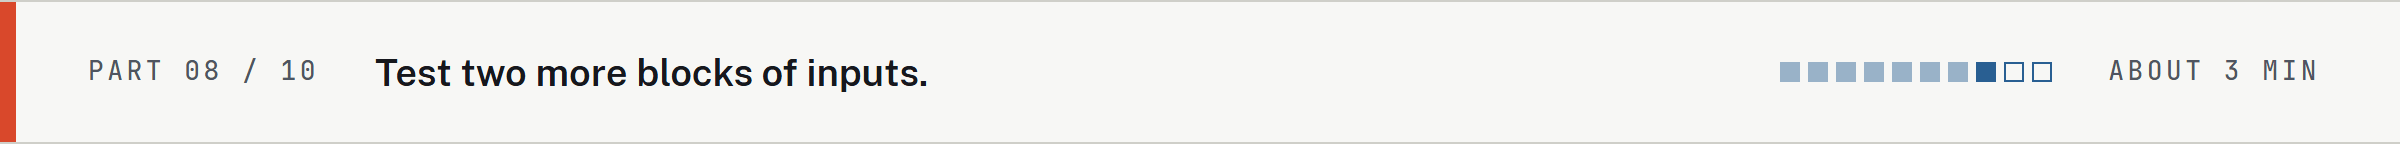

# Do Raw Dollars and Industry Earn Their Place

Two blocks of columns have waited since Chapter 1: the 17 dollar items and the industry codes.
Chapter 3 set the dollars aside, because a ratio compares firms of different size and a dollar amount does not.

A tree needs no common scale, so both blocks can be offered as they are.
Each is added to the full set of Chapter 3, ratios and history, under the frozen configuration.

The test is the paired difference against that set alone.

Q. What does each block add?

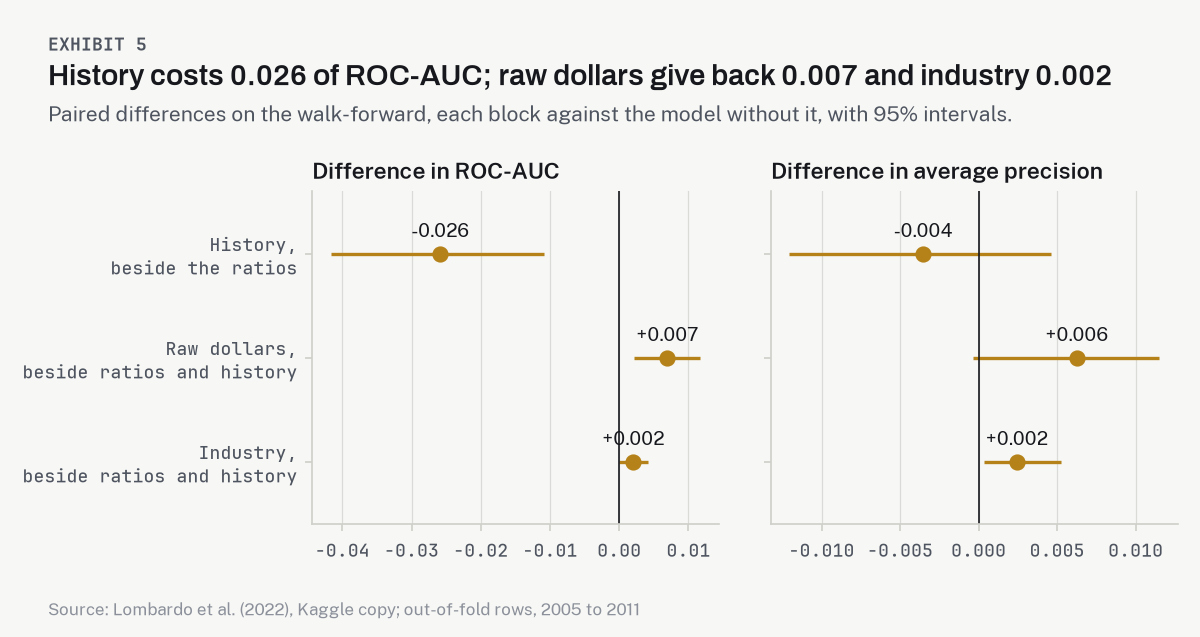

In [20]:
division = pd.get_dummies(dev["division"], prefix="division", dtype=int)
INDUSTRY = [*division.columns, "major_group"]
dev_industry = dev.join(division)


def industry_scores(train: pd.DataFrame, valid: pd.DataFrame) -> np.ndarray:
    """Ratios and history with clipped tails, and the industry columns beside them as they are."""
    prepare, *_ = fit_prepare(train, ALL, impute=False)
    model = trees(FROZEN, ROUNDS).fit(prepare(train).join(train[INDUSTRY]), train["target"])
    return model.predict_proba(prepare(valid).join(valid[INDUSTRY]))[:, 1]


blocks = {
    "Plus history": ladder["Plus history"],
    "Raw dollars": walk_forward_oof(tree_scores(FROZEN, [*ALL, *RAW_ITEMS], ROUNDS), dev, folds),
    "Industry": walk_forward_oof(industry_scores, dev_industry, folds),
}
block_steps = (
    pd.DataFrame(
        [
            history_step,
            paired_table(blocks, ["Plus history", "Raw dollars"]).iloc[0],
            paired_table(blocks, ["Plus history", "Industry"]).iloc[0],
        ]
    )
    .set_index("model")
    .drop(columns=["against", "usable"])
    .astype(float)
)
raw_step, industry_step = block_steps.loc["Raw dollars"], block_steps.loc["Industry"]
# The reading says raw dollars add a gain in ROC-AUC that is clear of zero, and that neither block
# brings the model back to the snapshot's level. Checked here.
assert raw_step["roc_auc_diff_lo"] > 0
assert all(
    roc_auc_score(blocks[name]["target"], blocks[name]["pct"])
    < roc_auc_score(ladder["All ratios, trees"]["target"], ladder["All ratios, trees"]["pct"])
    for name in ("Raw dollars", "Industry")
)

store.put("raw_step", raw_step["roc_auc_diff"])
store.put("raw_step_low", raw_step["roc_auc_diff_lo"])
store.put("raw_step_high", raw_step["roc_auc_diff_hi"])
store.put("industry_step", industry_step["roc_auc_diff"])
store.put("industry_step_low", industry_step["roc_auc_diff_lo"])
store.put("industry_step_high", industry_step["roc_auc_diff_hi"])
store.put("raw_share_of_tree_step", raw_step["roc_auc_diff"] / tree_step["roc_auc_diff"])

LABELS = [
    "History,\nbeside the ratios",
    "Raw dollars,\nbeside ratios and history",
    "Industry,\nbeside ratios and history",
]
fig, axes = plt.subplots(1, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 2.9), sharey=True)
place = np.arange(len(block_steps))[::-1]
for ax, key, name in zip(axes, ("roc_auc_diff", "ap_diff"), ("ROC-AUC", "average precision")):
    ax.hlines(place, block_steps[f"{key}_lo"], block_steps[f"{key}_hi"], color=TREES, linewidth=1.6)
    ax.scatter(block_steps[key], place, s=46, color=TREES, zorder=3)
    for y_at, value in zip(place, block_steps[key]):
        ax.annotate(f"{value:+.3f}", (value, y_at), xytext=(0, 8), textcoords="offset points",
                    ha="center", size=9)  # fmt: skip
    ax.axvline(0, color=viz.INK, linewidth=0.8)
    ax.set_title(f"Difference in {name}")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(place, LABELS)
axes[0].set_ylim(-0.6, len(block_steps) - 0.4)
viz.exhibit(
    fig,
    f"History costs {-history_step['roc_auc_diff']:.3f} of ROC-AUC; raw dollars give back "
    f"{raw_step['roc_auc_diff']:.3f} and industry {industry_step['roc_auc_diff']:.3f}",
    "Paired differences on the walk-forward, each block against the model without it, with 95% intervals.",
    OOF_SOURCE,
)

**Reading.** In Exhibit 5 raw dollars add 0.007 of ROC-AUC, with an interval from 0.002 to 0.012 that is clear of zero.
The gain is real and small, 27% of what trees added to the ratios.

Industry adds 0.0020, with an interval from -0.0001 to 0.0041.
Neither block brings the model back to where the snapshot stood.

**Next, telling the model what Chapter 3 already knows.**

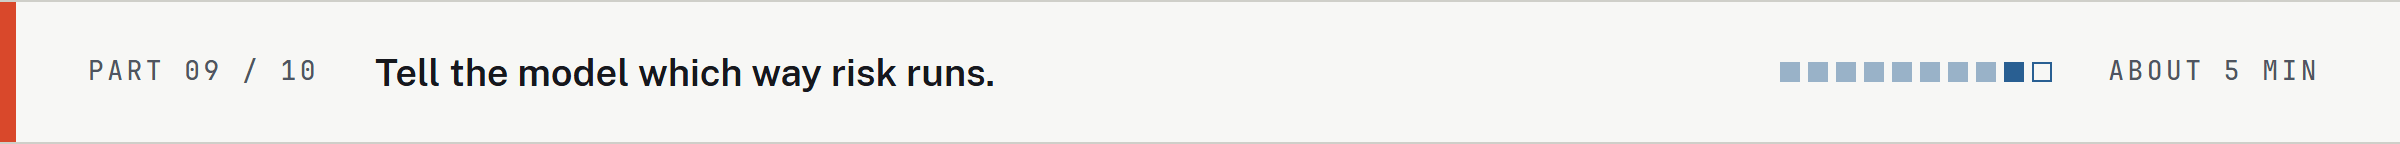

# Building In What We Know

A tree model is free to say that more leverage lowers risk over some stretch, if the training rows happen to lean that way.
A **monotone constraint** forbids it: the score may only rise, or only fall, as one input rises.

A constraint should come from evidence.
Chapter 3 drew the failure rate along each ratio and marked the curves that turn, and a ratio is constrained only where its curve does not turn.

Q. Which ratios get a constraint, and in which direction?

In [21]:
CONTINUOUS = [name for name in RATIOS if dev[name].nunique() > 2]
BINS = 10


def rate_by_bin(frame: pd.DataFrame, column: str) -> pd.DataFrame:
    """Two-year failure rate in each quantile bin of `column`, lowest first, with Wilson bounds."""
    rows = frame.dropna(subset=[column])
    bins = pd.qcut(rows[column], BINS, labels=False, duplicates="drop") + 1
    table = rows.groupby(bins)["target"].agg(positives="sum", rows="size")
    table["rate"] = table["positives"] / table["rows"]
    bounds = [wilson_interval(int(k), int(n)) for k, n in zip(table["positives"], table["rows"])]
    return table.join(pd.DataFrame(bounds, index=table.index, columns=["low", "high"]))


def turns(table: pd.DataFrame) -> bool:
    """True when a later bin's interval lies wholly on the wrong side of an earlier bin's."""
    rising = table["rate"].iloc[-1] > table["rate"].iloc[0]
    low, high = table["low"].to_numpy(), table["high"].to_numpy()
    pairs = [(i, j) for i in range(len(table)) for j in range(i + 1, len(table))]
    return any(high[j] < low[i] if rising else low[j] > high[i] for i, j in pairs)


def monotone_signs(rows: pd.DataFrame) -> dict[str, int]:
    """For each ratio: 1 if failure rises along it, -1 if it falls, 0 if its curve turns."""
    signs = {}
    for name in CONTINUOUS:
        table = rate_by_bin(rows, name)
        rising = table["rate"].iloc[-1] > table["rate"].iloc[0]
        signs[name] = 0 if turns(table) else (1 if rising else -1)
    return signs


WHY = {1: "failure rises along it", -1: "failure falls along it", 0: "its curve turns: left free"}
dev_signs = monotone_signs(dev)
fold_signs = pd.DataFrame({fold.year: monotone_signs(dev.loc[fold.train]) for fold in folds})
listing = pd.DataFrame({"constraint": dev_signs}).assign(
    why=lambda table: table["constraint"].map(WHY),
    folds_that_agree=fold_signs.eq(pd.Series(dev_signs), axis=0).sum(axis=1),
)

store.put("n_continuous", len(CONTINUOUS))
store.put("n_constrained", int((listing["constraint"] != 0).sum()))
store.put("n_turning", int((listing["constraint"] == 0).sum()))
store.put("n_stable", int((listing["folds_that_agree"] == len(folds)).sum()))

listing

,constraint,why,folds_that_agree
liabilities_to_assets,1,failure rises along it,7
lt_debt_to_assets,1,failure rises along it,7
book_equity_to_assets,-1,failure falls along it,7
debt_to_ebitda,1,failure rises along it,7
roa,-1,failure falls along it,4
ebit_to_assets,-1,failure falls along it,7
ebitda_to_assets,-1,failure falls along it,7
net_margin,-1,failure falls along it,1
ebitda_margin,-1,failure falls along it,6
gross_margin,-1,failure falls along it,5


**Reading.** The two functions above the list are Chapter 3's rule, typed again.
On the development rows, 18 of the 22 continuous ratios get a constraint, and 4 are left free because their curves turn.

The history columns and the two yes-or-no ratios are left free as well.

The last column counts the folds whose own training rows give the same answer, and it is 7 for 16 of the ratios.
So the list is a fitted thing, like a clipping bound, and each fold derives its own from its training rows.

Q. What do the constraints cost?

In [22]:
def constrained(train: pd.DataFrame, valid: pd.DataFrame) -> np.ndarray:
    """The frozen configuration on ratios and history, constrained by the training rows' own curves."""
    signs = monotone_signs(train)
    return tree_scores(FROZEN, ALL, ROUNDS, monotone_constraints=signs)(train, valid)


blocks["Monotone"] = walk_forward_oof(constrained, dev, folds)
monotone_step = paired_table(blocks, ["Plus history", "Monotone"]).iloc[0]
# The reading says the constraints do not help the ranking. Checked here.
assert monotone_step["roc_auc_diff"] < 0

store.put("monotone_step", monotone_step["roc_auc_diff"])
store.put("monotone_step_low", monotone_step["roc_auc_diff_lo"])
store.put("monotone_step_high", monotone_step["roc_auc_diff_hi"])

monotone_step.to_frame().T.set_index("model").drop(columns=["against", "usable"]).astype(
    float
).round(4)

,roc_auc_diff,roc_auc_diff_lo,roc_auc_diff_hi,ap_diff,ap_diff_lo,ap_diff_hi
model,,,,,,
Monotone,-0.0015,-0.0029,-0.0002,-0.0018,-0.0045,-0.0002


**Reading.** Against the same model left free, the constraints change ROC-AUC by -0.0015, with an interval from -0.0029 to -0.0002.
They do not help the ranking, and they cost it little.

Q. What do they change inside the model?

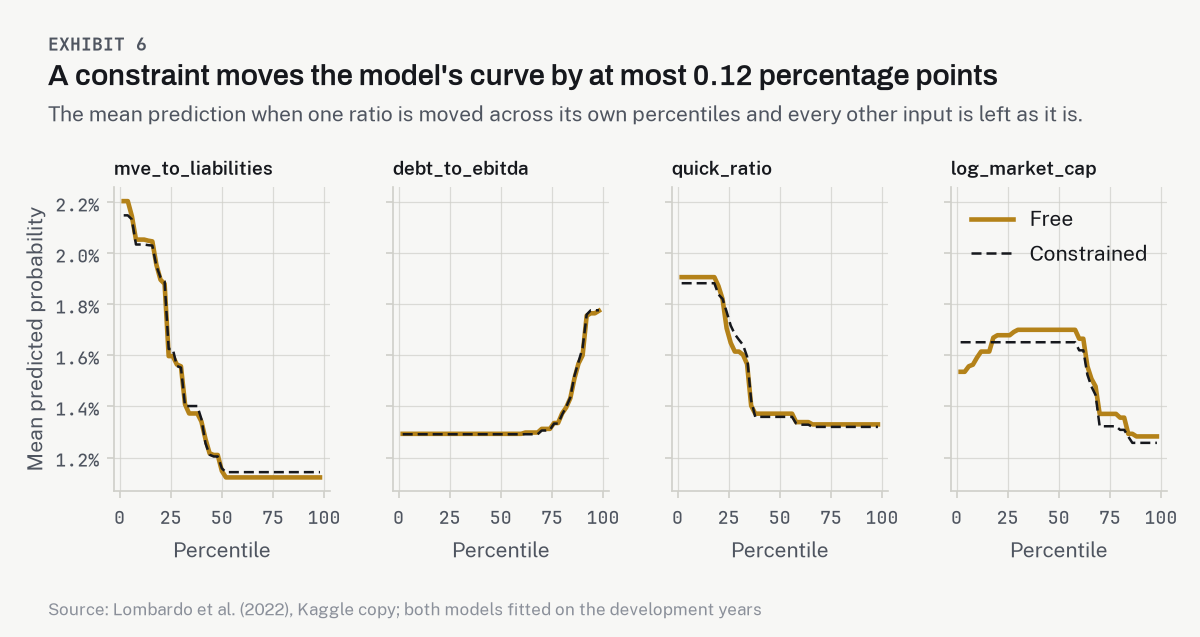

In [23]:
prepare_dev, *_ = fit_prepare(dev, ALL, impute=False)
inputs = prepare_dev(dev)
free = trees(FROZEN, ROUNDS).fit(inputs, dev["target"])
tied = trees(FROZEN, ROUNDS, monotone_constraints=dev_signs).fit(inputs, dev["target"])
sample = inputs.sample(2000, random_state=SEED)
QUANTILES = np.linspace(0.02, 0.98, 49)


def partial_dependence(model: XGBClassifier, name: str, values: np.ndarray) -> np.ndarray:
    """The model's mean prediction over the sample when every row's `name` is set to each value."""
    return np.array(
        [model.predict_proba(sample.assign(**{name: value}))[:, 1].mean() for value in values]
    )


# The four constrained ratios the free model leans on most, by the gain of its splits.
gain = pd.Series(free.get_booster().get_score(importance_type="total_gain"))
shown = gain[[name for name in gain.index if dev_signs.get(name)]].nlargest(4).index

fig, axes = plt.subplots(1, len(shown), figsize=(viz.EXHIBIT_WIDTH_IN, 2.9), sharey=True)
widest = 0.0
for ax, name in zip(axes, shown):
    values = np.quantile(inputs[name].dropna(), QUANTILES)
    loose, held = partial_dependence(free, name, values), partial_dependence(tied, name, values)
    widest = max(widest, float(np.abs(loose - held).max()))
    ax.plot(QUANTILES * 100, loose, color=TREES, linewidth=2.2, label="Free")
    ax.plot(QUANTILES * 100, held, color=viz.INK, linewidth=1.2, linestyle=(0, (4, 2)),
            label="Constrained")  # fmt: skip
    ax.set_title(name, size=9)
    ax.set_xlabel("Percentile")
    ax.xaxis.set_major_locator(MultipleLocator(25))
axes[0].set_ylabel("Mean predicted probability")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
axes[-1].legend(loc="upper right")

store.put("pd_widest", widest * 100)

viz.exhibit(
    fig,
    f"A constraint moves the model's curve by at most {widest * 100:.2f} percentage points",
    "The mean prediction when one ratio is moved across its own percentiles and every other input is left as it is.",
    f"{SOURCE}; both models fitted on the development years",
)

**Reading.** In Exhibit 6 the two models draw nearly the same curves.
The free model was close to monotone already, and where its curve wanders the constraint flattens it, by 0.12 percentage points at most.

So a constraint here buys a guarantee and not accuracy.
A lender can be told that no firm's score improves because its market value fell.

**Check.** Each fold derives its own list of constraints. What would go wrong if one list, from every development row, served all seven folds?

<details>
<summary>Show the answer</summary>

The list would have been chosen with the outcomes of the validation years in view, the same leak as a clipping bound fitted on every row.
It is a small leak, a yes or no for each ratio, and it would flatter the constrained model.

</details>

**Next, the five rungs together.**

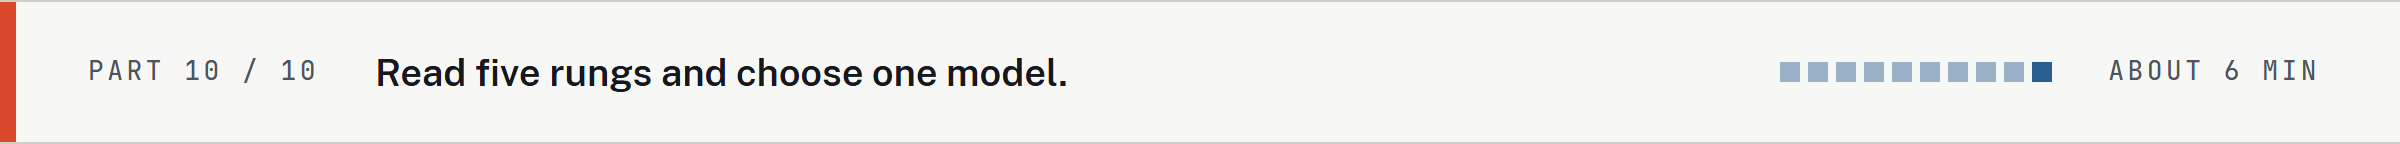

# The Ladder So Far

The chapter has walked 6 tree models forward: the snapshot, the snapshot with history, and four variations on that.
One of them goes forward, to be blended with a network in Chapter 6 and scored on the holdout in Chapter 7.

The rule is the one that chose the configuration: the highest mean average precision over the seven folds, each fold counting the same.

Q. Which tree model goes forward?

In [24]:
candidates = {
    "All ratios, trees": ladder["All ratios, trees"],
    "Plus history": ladder["Plus history"],
    "History, own search": own_oof,
    "Raw dollars": blocks["Raw dollars"],
    "Industry": blocks["Industry"],
    "Monotone": blocks["Monotone"],
}
mean_fold_ap = pd.Series(
    {name: ap_by_fold(oof).mean() for name, oof in candidates.items()}
).sort_values(ascending=False)
forward = mean_fold_ap.index[0]
# The reading says the snapshot model goes forward, by less than the noise of a seed. Checked here.
assert forward == "All ratios, trees"
assert mean_fold_ap.iloc[0] - mean_fold_ap.iloc[1] < by_seed.std()

store.put("n_candidates", len(candidates))
store.put("forward_ap", mean_fold_ap.iloc[0])
store.put("runner_up", mean_fold_ap.index[1])
store.put("runner_up_ap", mean_fold_ap.iloc[1])

mean_fold_ap.round(4).to_frame("mean average precision, seven folds")

,"mean average precision, seven folds"
"All ratios, trees",0.0795
Raw dollars,0.0782
"History, own search",0.0782
Industry,0.0766
Plus history,0.0737
Monotone,0.0697


**Reading.** The snapshot model goes forward, at 0.0795.
The nearest candidate, "Raw dollars", scores 0.0782.

The margin is smaller than the noise of a seed on a single fold, so the rule is choosing among near-equals.
It still lands on the smallest model, and nothing the chapter added after the search beat the 24 ratios.

Q. What do the five rungs score?

In [25]:
board = scoreboard(ladder).set_index("model")
snapshot, with_history = board.loc["All ratios, trees"], board.loc["Plus history"]

store.put("snapshot_auc", snapshot["roc_auc"])
store.put("snapshot_auc_low", snapshot["roc_auc_lo"])
store.put("snapshot_auc_high", snapshot["roc_auc_hi"])
store.put("snapshot_capture_5", snapshot["capture_5"])
store.put("history_auc", with_history["roc_auc"])
store.put("history_capture_5", with_history["capture_5"])
store.put("logistic_capture_5", board.loc["All ratios, logistic", "capture_5"])
# The readings say rung five finds no fewer failures at the middle budget, and ranks level with rung three.
assert with_history["capture_5"] >= snapshot["capture_5"]
assert abs(with_history["roc_auc"] - board.loc["All ratios, logistic", "roc_auc"]) < 0.005

board[["roc_auc", "roc_auc_lo", "roc_auc_hi", "ap", "capture_5", "lift_5", "accuracy_ratio"]].round(
    3
)

,roc_auc,roc_auc_lo,roc_auc_hi,ap,capture_5,lift_5,accuracy_ratio
model,,,,,,,
Altman Z,0.704,0.678,0.728,0.035,0.088,1.758,0.409
"Five ratios, refitted",0.662,0.634,0.692,0.033,0.086,1.719,0.325
"All ratios, logistic",0.750,0.728,0.773,0.051,0.170,3.400,0.500
"All ratios, trees",0.776,0.752,0.799,0.069,0.217,4.337,0.551
Plus history,0.750,0.723,0.778,0.065,0.232,4.650,0.499


**Reading.** The snapshot model has a ROC-AUC of 0.776, with an interval from 0.752 to 0.799.
At the middle budget it finds 21.7% of the failures, where the logistic regression found 17.0%.

Rung five scores 0.750, and at the middle budget it finds 23.2%.
History costs the ranking as a whole, yet at the middle budget, the part a desk reviews, it finds no fewer failures.

Q. What does each rung add to the one below it?

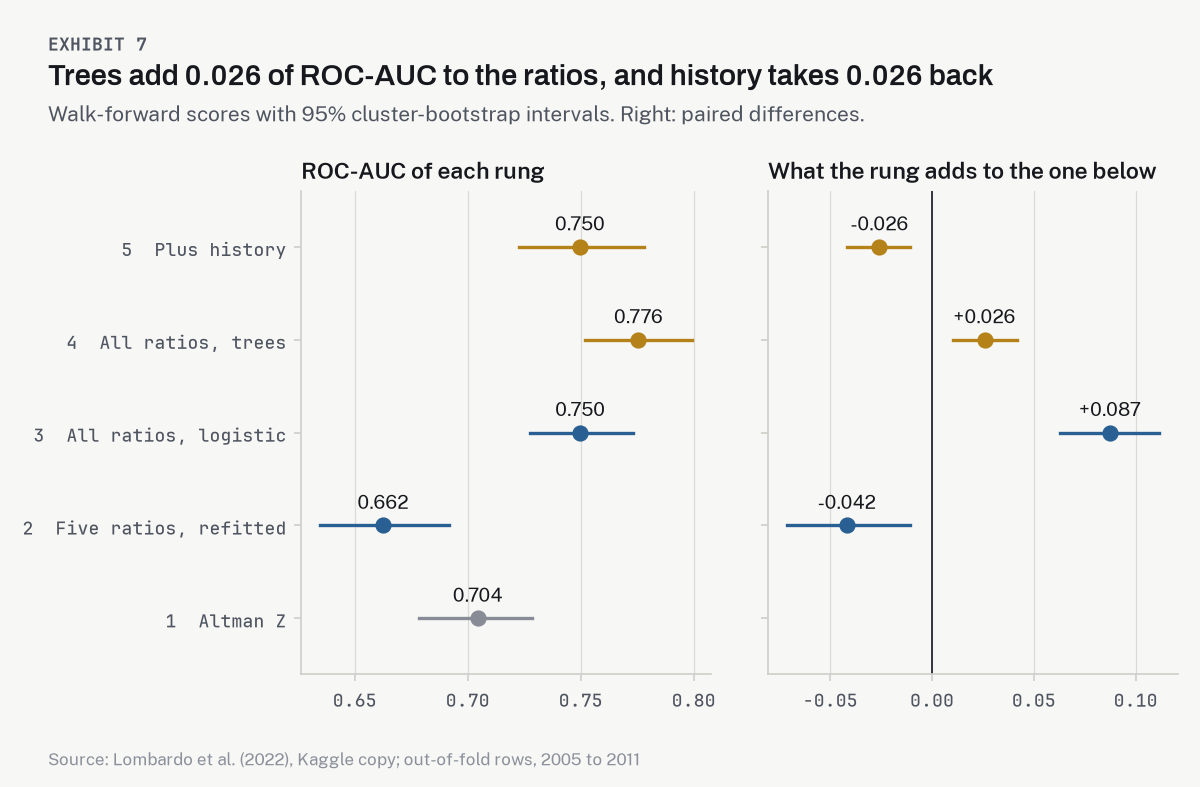

In [26]:
steps = paired_table(ladder, list(ladder)).set_index("model")

COLORS = [viz.MODEL_COLORS[kind] for kind in ("classic", "logistic", "logistic", "trees", "trees")]
fig, (level, step) = plt.subplots(1, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 3.9), sharey=True)
place = np.arange(len(ladder))
for y_at, (name, row), color in zip(place, board.iterrows(), COLORS):
    level.plot([row["roc_auc_lo"], row["roc_auc_hi"]], [y_at, y_at], color=color, linewidth=1.6)
    level.scatter(row["roc_auc"], y_at, s=46, color=color, zorder=3)
    level.annotate(f"{row['roc_auc']:.3f}", (row["roc_auc"], y_at), xytext=(0, 8),
                   textcoords="offset points", ha="center", size=9)  # fmt: skip
for y_at, (name, row), color in zip(place[1:], steps.iterrows(), COLORS[1:]):
    step.plot([row["roc_auc_diff_lo"], row["roc_auc_diff_hi"]], [y_at, y_at], color=color,
              linewidth=1.6)  # fmt: skip
    step.scatter(row["roc_auc_diff"], y_at, s=46, color=color, zorder=3)
    step.annotate(f"{row['roc_auc_diff']:+.3f}", (row["roc_auc_diff"], y_at), xytext=(0, 8),
                  textcoords="offset points", ha="center", size=9)  # fmt: skip
step.axvline(0, color=viz.INK, linewidth=0.8)
level.set_yticks(place, [f"{k + 1}  {name}" for k, name in enumerate(ladder)])
level.set_ylim(-0.6, len(ladder) - 0.4)
level.set_title("ROC-AUC of each rung")
level.xaxis.set_major_locator(MultipleLocator(0.05))
step.set_title("What the rung adds to the one below")
for ax in (level, step):
    ax.grid(axis="y", visible=False)
viz.exhibit(
    fig,
    f"Trees add {tree_step['roc_auc_diff']:.3f} of ROC-AUC to the ratios, and history takes "
    f"{-history_step['roc_auc_diff']:.3f} back",
    "Walk-forward scores with 95% cluster-bootstrap intervals. Right: paired differences.",
    OOF_SOURCE,
    save_as="ch5",
)

**Reading.** Exhibit 7 is the ladder so far.
The fourth rung is the highest: the same ratios, read by trees.

The fifth is a step down, back to the level of the logistic regression.
The ladder keeps it, because a rung is a question asked and not a prize given.

Q. Does the model that goes forward hold up in the crisis folds?

In [27]:
forward_folds = fold_table(ladder[forward]).set_index("fold")
crisis, calm = forward_folds.loc["crisis folds"], forward_folds.loc["calm folds"]

store.put("crisis_auc", crisis["roc_auc"])
store.put("crisis_auc_low", crisis["roc_auc_lo"])
store.put("crisis_auc_high", crisis["roc_auc_hi"])
store.put("calm_auc", calm["roc_auc"])
store.put("calm_auc_low", calm["roc_auc_lo"])
store.put("calm_auc_high", calm["roc_auc_hi"])
# The reading says the two intervals overlap. Checked here.
assert crisis["roc_auc_hi"] > calm["roc_auc_lo"]

forward_folds[["rows", "positives", "roc_auc", "roc_auc_lo", "roc_auc_hi", "capture_5"]].round(3)

,rows,positives,roc_auc,roc_auc_lo,roc_auc_hi,capture_5
fold,,,,,,
2005,4165,105,0.729,0.680,0.776,0.162
2006,4077,114,0.767,0.725,0.810,0.228
2007,3950,79,0.816,0.762,0.858,0.266
2008,3799,57,0.760,0.701,0.816,0.211
2009,3720,59,0.765,0.703,0.819,0.169
2010,3590,47,0.827,0.780,0.874,0.213
2011,3488,51,0.811,0.753,0.862,0.294
crisis folds,12192,298,0.767,0.733,0.799,0.215
calm folds,14597,214,0.788,0.756,0.822,0.220


**Reading.** The snapshot model ranks at 0.767 in the crisis folds, with an interval from 0.733 to 0.799.
In the calm folds it ranks at 0.788, from 0.756 to 0.822, so the two intervals overlap.

Q. What does the chapter hand on?

In [28]:
oof_scores = pd.concat(
    [earlier, *(ladder[name].assign(model=name) for name in NEW)], ignore_index=True
)
frozen = {name: spec for name, spec in store.load_json("frozen").items() if name not in NEW}
for name, columns in {"All ratios, trees": RATIOS, "Plus history": ALL}.items():
    frozen[name] = {
        "kind": "gradient boosting",
        "features": columns,
        "params": FROZEN,
        "rounds": ROUNDS,
        "forward": name == forward,
    }
store.save_frame("oof_scores", oof_scores)
store.save_json("frozen", frozen)

oof_scores.groupby("model", sort=False)["target"].agg(rows="size", positives="sum")

,rows,positives
model,,
Altman Z,26789,512
"Five ratios, refitted",26789,512
"All ratios, logistic",26789,512
"All ratios, trees",26789,512
Plus history,26789,512


**Reading.** The table of scores now holds five rungs on the same rows, and the record marks the snapshot model as the tree that goes forward.

**The next chapter asks whether a network can read the history that the trees could not use.**

# Findings

1. One tree three questions deep gives a handful of scores, and boosting adds small trees until the map of risk is fine, and then until it is noisy (Exhibit 1).
2. Changing only the seed moves average precision on one fold by 0.005, more than the 0.0013 between the two best configurations on that fold (Exhibit 2).
3. Seven folds choose trees 2 questions deep and 200 rounds; a single window's winner scores 0.089 on its window and 0.068 elsewhere (Exhibit 3).
4. Trees add 0.026 of ROC-AUC to the same 24 ratios, with an interval above zero (Exhibit 7).
5. History takes it back: -0.026, with an interval below zero, and a search of its own does not rescue it (Exhibit 7).
6. History costs 0.031 of ROC-AUC in the folds that train on the panel's first years and adds 0.020 in the later ones (Exhibit 4).
7. Raw dollars add 0.007 and industry 0.002, and monotone constraints move the model's curves by at most 0.12 percentage points (Exhibit 5, Exhibit 6).

# Your Turn

Three extensions, each with a hint folded under it.

**1. Beyond the edge.** The search chose the shallowest tree and the slowest learning rate on offer. Does a model of one question to a tree, or a slower rate, score higher?

<details>
<summary>Hint</summary>

Add `1` to `max_depth` and `0.01` to `learning_rate` in `SPACE`, and raise the largest value in `CUTOFFS`, since a slower model needs more rounds.
Then run `search(RATIOS)` and `choose` again.

</details>

**2. A later start.** Train every fold on rows from 2001 on, so that every training year can show a two-year change. Does history still lose in the early folds?

<details>
<summary>Hint</summary>

Write a `fit_predict` that drops the training rows before 2001 and then calls `tree_scores(FROZEN, ALL, ROUNDS)`.
Do the same for `RATIOS`, so the two models are trained on the same rows, and compare them fold by fold.

</details>

**3. Dollars beside the ratios.** Raw dollars were tested beside ratios and history. What do they add to the snapshot model alone?

<details>
<summary>Hint</summary>

Score `tree_scores(FROZEN, [*RATIOS, *RAW_ITEMS], ROUNDS)` with `walk_forward_oof`.
Pass it to `paired_table` with `ladder["All ratios, trees"]`.

</details>

[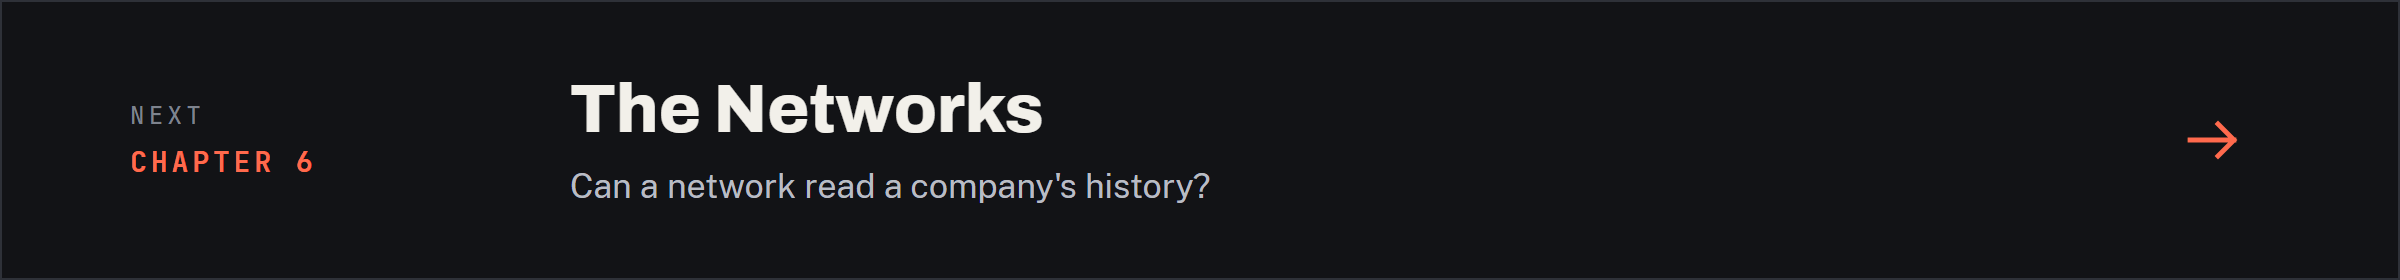](06_the_networks.ipynb)